# Full satellite time-series analysis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/analisis_completo.ipynb) [![License: GPL-3.0](https://img.shields.io/badge/license-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

One notebook, no `utils/`: edit the configuration cell and run everything from top to bottom. Every step is split into independent cells: **functions** (definitions only), **prepare** (search, load, transform), **extract** (values at your points) and **plot**.

| Part | Products (saved in `outputs/`) |
|---|---|
| Sentinel-2 scene of an area | `sentinel2_scene.png`: true color, false color, NDWI, turbidity, chlorophyll and NDVI |
| Sentinel-2 series at your points | `sentinel2_series.parquet` (with metadata), `sentinel2_summary.csv`, exploration figures |
| Interactive products | `interactive_series.html` and `points_map.html` |
| Landsat 8/9 series at your points | `landsat_series.parquet` (surface temperature and reflectance, with metadata) |
| Extreme events | `landsat_episodes.parquet` (hot and cold episodes), Isolation Forest comparison, figures |
| Optional 500 m grid | `grid_anomaly_frequency.png`: how often each pixel is above the hot or below the cold threshold |

## 1. Install packages

In [1]:
import importlib
import subprocess
import sys

PACKAGES = {"pystac-client": "pystac_client", "planetary-computer": "planetary_computer", "odc-stac": "odc.stac", "hvplot": "hvplot",
            "folium": "folium", "scikit-learn": "sklearn"}  # the last two already come with Colab


def missing(module):
    try:
        importlib.import_module(module)
        return False
    except ImportError:
        return True


to_install = [package for package, module in PACKAGES.items() if missing(module)]
if to_install:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *to_install], check=True)
print("Installed:", ", ".join(to_install) if to_install else "nothing was missing")

Installed: pystac-client, planetary-computer, odc-stac, hvplot


## 2. Import libraries

In [2]:
import base64
import hashlib
import io
import json
import math
import os
import re
import time
import warnings
from datetime import date, timedelta
from pathlib import Path

import dask
import folium
import hvplot
import hvplot.pandas  # noqa: F401  (adds the .hvplot accessor to pandas)
import matplotlib.pyplot as plt
import numpy as np
import odc.stac
import pandas as pd
import planetary_computer
import pyarrow as pa
import pyarrow.parquet as pq
import pystac_client
import xarray as xr
from pyproj import Transformer
from shapely.geometry import box, shape
from sklearn.ensemble import IsolationForest

# Fast COG reading over the internet: big header cache and several requests per connection
os.environ.setdefault("CPL_VSIL_CURL_CACHE_SIZE", "1000000000")
os.environ.setdefault("GDAL_CACHEMAX", "1024")
os.environ.setdefault("GDAL_HTTP_MULTIPLEX", "YES")
warnings.filterwarnings("ignore", category=UserWarning)  # GDAL warnings for scenes without georeference
warnings.filterwarnings("ignore", category=RuntimeWarning)  # medians of empty windows (all clouds)
hvplot.extension("bokeh")
odc.stac.configure_rio(cloud_defaults=True)  # retries and efficient COG reading over the internet
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Colorblind-safe palette (Okabe-Ito), one color per point
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
RED, BLUE, GRAY = "#c0392b", "#2471a3", "#7f8c8d"

## 3. Configuration (edit this cell)

In [3]:
POINTS_CSV = None
POINTS = pd.DataFrame([
    ("bahia_cant",  "Bahía de Cañete",      20.580257, -74.715581, "bahia"),
    ("bahia_taco",  "Bahía de Taco",        20.518230, -74.671196, "bahia"),
    ("bahia_nibj",  "Nibujón",              20.493565, -74.620637, "bahia"),
    ("frente_agua", "Frente de Yamanigüey", 20.563864, -74.676098, "mar"),
], columns=["id", "name", "lat", "lon", "type"])


# --- Sentinel-2 ---
DATES_S2 = ("2021-10-01", "2026-09-30")  # series period (one year shows the seasonal cycle)
MAX_CLOUD_S2 = 60  # scene filter: maximum cloud cover (%) of the whole image
RADIUS_S2 = 100  # radius (m) of the window around each point
MIN_FRACTION = 0.5  # a date counts if at least this fraction of the window passed the mask
EXCLUDE_SCL = [0, 1, 3, 8, 9, 10]  # discarded SCL classes: no data, saturated, shadow, medium cloud, high cloud, cirrus
AREA = [POINTS["lon"].min() - 0.05, POINTS["lat"].min() - 0.05,
        POINTS["lon"].max() + 0.05, POINTS["lat"].max() + 0.05]
SCENE_DATE = "2025-11-16"  # "YYYY-MM-DD", or None for the clearest date of DATES_S2
SCENE_RESOLUTION = 10  # m (use 20 or 60 if your area is large)

# --- detalle ---
POINT = "bahia_cant"   # el punto con más datos (44 valores de NDWI)
VARIABLE = "ndwi"      # o "b04" si quieres usar bahia_taco

# --- Landsat Primera prueba---
DATES_LANDSAT = ("2013-03-01", "2026-09-30")  # final prueba
BASE = (2014, 2024)  # años completos de la climatología
RADIUS_LANDSAT = 150  # radius (m) of the window around each point
MAX_CLOUD_LANDSAT = 90  # loose scene filter: the pixel mask does the fine work
WATER_TYPES = ["bahia", "mar"]  # values of the `type` column that are open water
PERCENTILE = 90  # hot threshold (the cold one is 100 minus this value)
CLIM_MIN_OBS = 8  # minimum observations in a climatology window
MIN_OBS = 2  # minimum consecutive observations of an episode
MAX_GAP_DAYS = 24  # maximum days between two observations of the same episode
CONTAMINATION = 0.1  # fraction of observations that Isolation Forest flags as outliers

# --- 500 m grid (optional) ---
RUN_GRID = False  # True to run the grid (slow: reads every scene of the area)
GRID_AREA = [-73.6, -37.35, -72.8, -36.55]  # west, south, east, north
GRID_RESOLUTION = 500  # m
GRID_YEARS = (2025, 2026)  # years used to count the fraction of anomalies
GRID_T_MIN = 3  # deg C: below this value we assume unmarked cloud (adjust it to your area)

# --- Outputs ---
OUTPUTS = Path("outputs")  # results folder (in Colab it is /content/outputs)
REUSE = True  # reuse the saved Landsat series if the configuration did not change

## 4. Common functions

In [4]:
def utm_crs(lon, lat):
    """UTM CRS (EPSG) of the zone of a point, for example EPSG:32718 in Concepcion."""
    zone = int((lon + 180) // 6) + 1
    return f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"


def to_utm(lon, lat, crs):
    """Degrees to meters of the given CRS."""
    return Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(lon, lat)


def point_bbox(lon, lat, radius_m):
    """Rectangle [west, south, east, north] of `radius_m` meters around a point."""
    dlat = radius_m / 111_320
    dlon = radius_m / (111_320 * math.cos(math.radians(lat)))
    return [lon - dlon, lat - dlat, lon + dlon, lat + dlat]


def points_bbox(points, radius_m):
    """Rectangle that contains the windows of all points (one STAC search and one lazy cube)."""
    boxes = np.array([point_bbox(p.lon, p.lat, radius_m) for p in points.itertuples()])
    return [float(boxes[:, 0].min()), float(boxes[:, 1].min()), float(boxes[:, 2].max()), float(boxes[:, 3].max())]


def window_mask(data, x, y, radius_m):
    """Mask of the pixels within `radius_m` meters of (x, y); if there are none, the nearest pixel."""
    distance = np.hypot(data["x"] - x, data["y"] - y)
    inside = distance <= radius_m
    return inside if bool(inside.any()) else distance == distance.min()


def normalized_difference(a, b):
    """(a - b) / (a + b), between -1 and 1; anything else becomes NaN."""
    index = (a - b) / (a + b)
    return index.where(np.abs(index) <= 1)


def search_stac(collection, bbox, dates, max_cloud=100, platforms=None):
    """Native STAC search: items of a collection with less than `max_cloud` % of scene cloud cover."""
    query = {"eo:cloud_cover": {"lt": max_cloud}}
    if platforms:
        query["platform"] = {"in": platforms}
    for attempt in range(3):  # a passing network error should not stop the notebook
        try:
            search = catalog.search(collections=[collection], bbox=bbox, datetime=f"{dates[0]}/{dates[1]}", query=query)
            return list(search.items())
        except Exception as error:
            if attempt == 2:
                raise
            print(f"Search failed ({type(error).__name__}); retry {attempt + 1} of 2")
            time.sleep(5)


def compute_all(lazy, workers=32, retries=2):
    """Read in parallel every lazy object of a dict (a single pass over the data); repeat if a network read fails."""
    for attempt in range(retries + 1):
        try:
            return dask.compute(lazy, scheduler="threads", num_workers=workers)[0]
        except Exception as error:
            if attempt == retries:
                raise
            print(f"A read failed ({type(error).__name__}); retry {attempt + 1} of {retries}")


def lazy_windows(items, points, radius_m, load, transform):
    """One small lazy cube per point, with only the images that touch its window, already transformed.

    `load(items, bbox, crs)` builds the lazy DN cube and `transform(cube)` calibrates and masks it. Nothing is read yet."""
    windows = {}
    for p in points.itertuples():
        bbox = point_bbox(p.lon, p.lat, radius_m)
        touching = [i for i in items if shape(i.geometry).intersects(box(*bbox))]
        if touching:
            windows[p.id] = transform(load(touching, bbox, utm_crs(p.lon, p.lat)))
        else:
            print(f"Warning: no image covers {p.id}")
    return windows


def summarize_windows(windows, points, radius_m, min_valid, keep):
    """Read all windows in one parallel pass and take the median of every variable in the circle of `radius_m` around each point.

    The cubes need two 0/1 layers, `valid` (passed the mask) and `covered` (the image covers the pixel). `keep` lists the coordinates
    of `time` copied to the table. Returns one row per point and date; dates with less than `min_valid` of the window valid keep their row with NaN values."""
    windows = compute_all(windows)
    tables = []
    for p in points.itertuples():
        if p.id not in windows:
            continue
        window = windows[p.id]
        variables = [v for v in window.data_vars if v not in ("valid", "covered")]
        x, y = to_utm(p.lon, p.lat, utm_crs(p.lon, p.lat))
        inside = window_mask(window, x, y, radius_m)
        median = window[variables].where(inside).median(("y", "x"))
        table = pd.DataFrame({v: median[v].values for v in variables}, index=pd.Index(window["time"].values, name="date"))
        for name in keep:
            table[name] = window[name].values
        table["valid_pixels"] = window["valid"].where(inside).mean(("y", "x")).values
        table["n_pixels"] = int(inside.sum())
        table = table[window["covered"].where(inside).mean(("y", "x")).values > 0.5]  # the window must be at least half inside the image
        table.loc[table["valid_pixels"] < min_valid, variables] = np.nan
        tables.append(table.reset_index().assign(id=p.id))
    return pd.concat(tables, ignore_index=True)


def save_parquet(table, path, metadata):
    """Save the table as parquet with the metadata inside the same file (the FAIR moment)."""
    arrow_table = pa.Table.from_pandas(table, preserve_index=False)
    meta = dict(arrow_table.schema.metadata or {})
    for key, value in metadata.items():
        meta[key.encode()] = (value if isinstance(value, str) else json.dumps(value, ensure_ascii=False)).encode()
    pq.write_table(arrow_table.replace_schema_metadata(meta), path, compression="zstd")


def read_metadata(path):
    """Metadata of a parquet file as a text dict (the "pandas" key is not interesting)."""
    return {k.decode(): v.decode() for k, v in pq.read_schema(path).metadata.items() if k != b"pandas"}


def series_of(table, point, variable, dropna=True):
    """Series of a variable at a point: pandas.Series indexed by date."""
    series = table[table["id"] == point].set_index("date")[variable].astype(float).sort_index()
    return series.dropna() if dropna else series

## 5. Points and STAC catalog

In [5]:
OUTPUTS.mkdir(exist_ok=True)
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", timeout=60)  # Planetary Computer

points = pd.read_csv(POINTS_CSV, dtype={"id": str, "name": str, "type": str}) if POINTS_CSV else POINTS.copy()
absent = [c for c in ["id", "name", "lat", "lon", "type"] if c not in points.columns]
assert not absent, f"Your points table is missing the columns {absent}"
assert points["id"].is_unique, "There are repeated ids"
assert points["lat"].between(-90, 90).all() and points["lon"].between(-180, 180).all(), "lat or lon out of range (are they swapped?)"
points = points[["id", "name", "lat", "lon", "type"]].reset_index(drop=True)
if POINT not in set(points["id"]):
    print(f"POINT = {POINT!r} is not in your table: using {points['id'].iloc[0]!r}")
    POINT = points["id"].iloc[0]
colors = {identifier: PALETTE[i % len(PALETTE)] for i, identifier in enumerate(points["id"])}
print(f"{len(points)} points | Sentinel-2: {DATES_S2[0]} to {DATES_S2[1]} | Landsat: {DATES_LANDSAT[0]} to {DATES_LANDSAT[1]}")

4 points | Sentinel-2: 2021-10-01 to 2026-09-30 | Landsat: 2013-03-01 to 2026-09-30


In [6]:
for p in points.itertuples():
    t = search_stac("landsat-c2-l2", point_bbox(p.lon, p.lat, RADIUS_LANDSAT), ("2023-01-01", "2023-12-31"),
                    MAX_CLOUD_LANDSAT, platforms=["landsat-8", "landsat-9"])
    print(f"{p.id:12s} {len(t):3d} escenas, {sum('lwir11' in i.assets for i in t):3d} con lwir11")

bahia_cant    82 escenas,  82 con lwir11
bahia_taco    81 escenas,  81 con lwir11
bahia_nibj    45 escenas,  45 con lwir11
frente_agua   82 escenas,  82 con lwir11


## 6. Sentinel-2 functions: offset rules, load and transform

Sentinel-2 L2A reflectance is `DN * 0.0001 + offset`. The **offset depends on the processing baseline of each image**: `-0.1` from baseline 04.00 and `0` before. It is decided image by image, never as one constant for the whole series. `group_day_offset` is passed to `odc.stac.load` so images with different offsets are never mixed in one date. Sometimes two tiles of the same acquisition have the exact same time and different offsets (one reprocessed with baseline 04.00 and one not): `break_date_ties` shifts the second group by 1 ms so every date is unique. These functions are for Sentinel-2 from Planetary Computer only.

In [7]:
def offset_item(item):
    """Reflectance offset of an image according to its processing baseline."""
    baseline = float(item.properties["s2:processing_baseline"])  # "05.11" -> 5.11
    return -0.1 if baseline >= 4.0 else 0.0  # baseline 04.00 or later: 1000 was added to the DN


def group_day_offset(item, parsed=None, idx=None):
    """odc.stac grouping key: (solar day, offset). Images of the same day and offset form one date."""
    lon = (item.bbox[0] + item.bbox[2]) / 2
    return ((item.datetime + timedelta(hours=lon / 15)).date().isoformat(), offset_item(item))


def remove_duplicates(items):
    """Only one version of each acquisition (same satellite, tile and datastrip): the one with the highest baseline."""
    best = {}
    for item in items:
        datastrip = re.search(r"_S(\d{8}T\d{6})_", item.properties.get("s2:datastrip_id") or "")
        acquisition = (item.properties["platform"], item.properties["s2:mgrs_tile"], datastrip.group(1) if datastrip else item.datetime.isoformat())
        version = (tuple(int(n) for n in item.properties["s2:processing_baseline"].split(".")), item.properties.get("s2:generation_time", ""), item.id)
        if acquisition not in best or version > best[acquisition][0]:
            best[acquisition] = (version, item)
    return sorted((item for _, item in best.values()), key=lambda item: (item.datetime, item.id))


def break_date_ties(items):
    """If two (day, offset) groups have the exact same time, shift the second by 1 ms so every date is unique."""
    items = list(items)
    groups = {}
    for i, item in enumerate(items):
        groups.setdefault(group_day_offset(item), []).append(i)
    taken = set()
    for key in sorted(groups):
        first = min(items[i].datetime for i in groups[key])
        shift = timedelta(0)
        while first + shift in taken:
            shift += timedelta(milliseconds=1)
        taken.add(first + shift)
        if shift:
            for i in groups[key]:
                items[i] = items[i].clone()  # copy: the original item does not change
                items[i].datetime += shift
    return sorted(items, key=lambda item: (item.datetime, item.id))


def add_metadata(data, items):
    """Add to `data` the reflectance offset and the scene cloud cover of each date (coordinates of `time`)."""
    groups = {}
    for item in items:
        groups.setdefault(group_day_offset(item), []).append(item)
    by_date = {}
    for (_, offset), group in groups.items():
        clouds = float(np.mean([i.properties["eo:cloud_cover"] for i in group]))
        for item in group:
            stamp = np.datetime64(item.datetime.replace(tzinfo=None), "ns")
            if stamp in by_date and by_date[stamp][0] != offset:
                raise ValueError(f"Two groups with different offsets have the same exact time ({stamp}): pass the items through break_date_ties()")
            by_date[stamp] = (offset, clouds)
    dates = [by_date[t] for t in data["time"].values.astype("datetime64[ns]")]
    return data.assign_coords(reflectance_offset=("time", [d[0] for d in dates]), cloud_scene=("time", [d[1] for d in dates]))


def reflectance_sentinel2(data):
    """DN to reflectance with the offset of each date. Convert before combining dates (for example before a median over time)."""
    refl = data.where(data != 0) * 0.0001 + data["reflectance_offset"]  # DN 0 = no data
    refl = refl.where((refl >= 0) & (refl <= 1))  # a valid reflectance is between 0 and 1
    return refl.drop_vars("reflectance_offset")

In [8]:
S2_SPECTRAL = ["B03", "B04", "B05", "B08"]  # green, red, red edge and NIR (the scene also loads B02, blue)
S2_INDICES = ["ndwi", "ndci", "b04", "ndvi"]


def load_sentinel2(items, bbox, crs, resolution, bands, chunk):
    """Lazy (dask) cube of DN: one date per (day, offset) group, with offset and scene cloud cover as coordinates."""
    cube = odc.stac.load(items, bands=bands, crs=crs, resolution=resolution, bbox=bbox, chunks={"x": chunk, "y": chunk},
                         groupby=group_day_offset, patch_url=planetary_computer.sign)
    return add_metadata(cube, items)


def sentinel2_indices(refl):
    """The four variables of the course from a reflectance Dataset: NDWI (water), NDCI (chlorophyll), B04 (turbidity) and NDVI."""
    return xr.Dataset({"ndwi": normalized_difference(refl["B03"], refl["B08"]),
                       "ndci": normalized_difference(refl["B05"], refl["B04"]),
                       "b04": refl["B04"],
                       "ndvi": normalized_difference(refl["B08"], refl["B04"])})


def sentinel2_products(cube):
    """Whole cube at once: SCL mask, reflectance of all bands with the offset of each date and the four indices.

    Adds the `valid` and `covered` layers and keeps the offset and the scene cloud cover as coordinates."""
    scl = cube["SCL"]
    covered = scl.notnull() & (scl != 0)  # the image covers the pixel
    valid = covered & ~scl.isin(EXCLUDE_SCL)  # and its class is not in the discarded list
    products = sentinel2_indices(reflectance_sentinel2(cube[S2_SPECTRAL].where(valid)))
    products["valid"], products["covered"] = valid.astype("float32"), covered.astype("float32")
    return products.assign_coords(reflectance_offset=cube["reflectance_offset"], cloud_scene=cube["cloud_scene"])

## 7. Sentinel-2 scene: search

One search for the area; we keep the clearest date of the period (or the one you fixed in `SCENE_DATE`).

In [9]:
area_items = break_date_ties(remove_duplicates(search_stac("sentinel-2-l2a", AREA, DATES_S2)))
days = pd.DataFrame({"day": [group_day_offset(i)[0] for i in area_items], "clouds": [i.properties["eo:cloud_cover"] for i in area_items]})
clouds_by_day = days.groupby("day")["clouds"].mean()
scene_date = SCENE_DATE or clouds_by_day.idxmin()
scene_items = [i for i in area_items if group_day_offset(i)[0] == scene_date]
print(f"{len(area_items)} images over the area. Scene: {scene_date}, {len(scene_items)} image(s), clouds {clouds_by_day[scene_date]:.1f} %")

753 images over the area. Scene: 2025-11-16, 1 image(s), clouds 4.1 %


In [10]:
from shapely.ops import unary_union
from shapely.geometry import Point

by_date = {}
for it in area_items:
    by_date.setdefault(it.datetime.date().isoformat(), []).append(it)
rows = []
for d, its in by_date.items():
    union = unary_union([shape(i.geometry) for i in its])
    covered = sum(union.contains(Point(p.lon, p.lat)) for p in points.itertuples())
    rows.append((d, len(its), covered, round(sum(i.properties["eo:cloud_cover"] for i in its) / len(its), 1)))
cov = pd.DataFrame(rows, columns=["date", "images", "points_covered", "clouds"]).sort_values(["points_covered", "clouds"], ascending=[False, True])
print(cov.head(10).to_string(index=False))

      date  images  points_covered  clouds
2022-12-27       1               4     1.6
2022-12-17       2               4     2.4
2023-03-12       1               4     3.5
2022-10-18       1               4     3.8
2025-03-06       1               4     4.0
2025-11-16       1               4     4.1
2024-10-02       1               4     4.2
2023-07-15       1               4     4.4
2023-04-21       1               4     4.5
2025-12-31       1               4     4.5


## 8. Sentinel-2 scene: load

The load is lazy: it builds the cube and `.compute()` reads only the needed blocks of each COG. Six bands: the five spectral ones and the scene classification (`SCL`).

In [11]:
scene_bands = ["B02", "B03", "B04", "B05", "B08", "SCL"]
center_lon, center_lat = (AREA[0] + AREA[2]) / 2, (AREA[1] + AREA[3]) / 2
area_crs = utm_crs(center_lon, center_lat)

lazy_scene = load_sentinel2(scene_items, AREA, area_crs, SCENE_RESOLUTION, scene_bands, chunk=1024)
print(f"{lazy_scene.sizes['x']} x {lazy_scene.sizes['y']} pixels of {SCENE_RESOLUTION} m, {lazy_scene.nbytes / 1e6:.0f} MB to read")
t0 = time.time()
scene = lazy_scene.compute()
print(f"Read in {time.time() - t0:.0f} s")

2037 x 2071 pixels of 10 m, 101 MB to read
Read in 13 s


## 9. Sentinel-2 scene: reflectance and indices

All bands are converted at once with the offset of the image, then the indices. Very dark pixels can give slightly negative reflectance: they stay `NaN`.

In [12]:
scene_refl = reflectance_sentinel2(scene[["B02", *S2_SPECTRAL]]).mean("time")  # normally one group; if there are several they are averaged
scene_indices = sentinel2_indices(scene_refl)
is_water = scene_indices["ndwi"] > 0
print(f"{float(is_water.mean()):.0%} of the area is water (NDWI > 0)")

11% of the area is water (NDWI > 0)


## 10. Sentinel-2 scene: plot

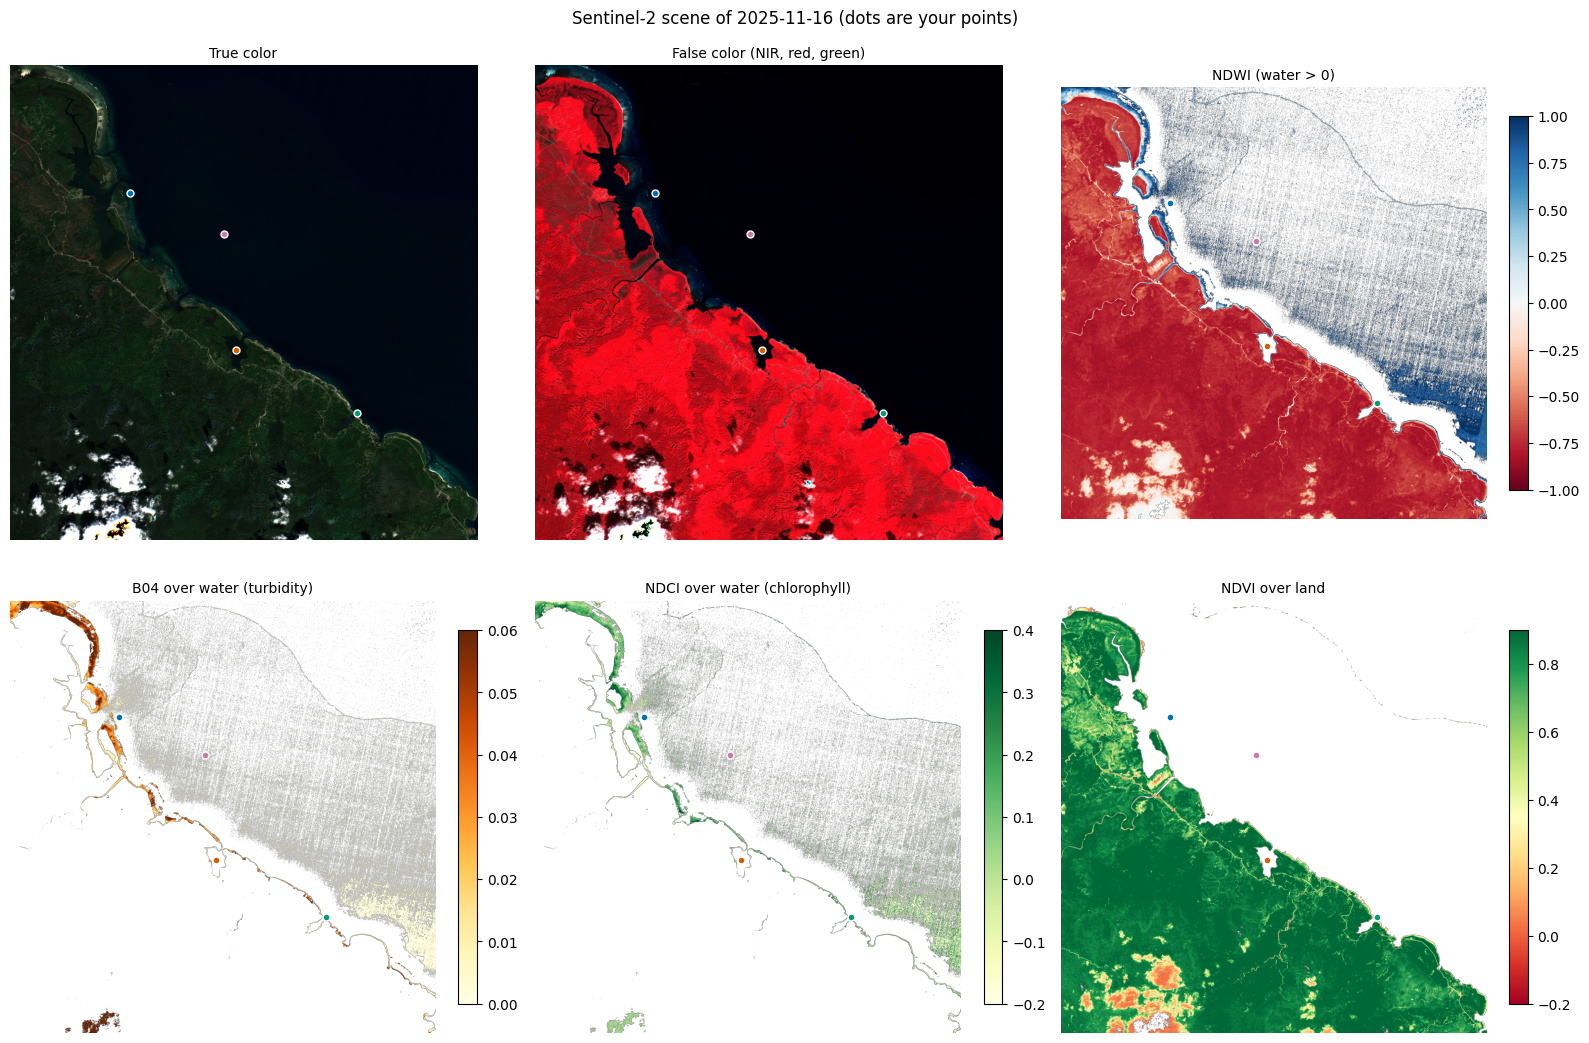

In [13]:
def rgb_image(refl, bands, gain=3.5):
    """Stack three bands as (height, width, 3), multiply by a brightness gain and clip between 0 and 1."""
    return np.clip(np.dstack([refl[b].fillna(0).values for b in bands]) * gain, 0, 1)


extent = [float(scene["x"].min()), float(scene["x"].max()), float(scene["y"].min()), float(scene["y"].max())]
points_utm = {p.id: to_utm(p.lon, p.lat, area_crs) for p in points.itertuples()}
panels = [
    ("True color", rgb_image(scene_refl, ["B04", "B03", "B02"]), {}),
    ("False color (NIR, red, green)", rgb_image(scene_refl, ["B08", "B04", "B03"], 3.0), {}),
    ("NDWI (water > 0)", scene_indices["ndwi"].values, {"cmap": "RdBu", "vmin": -1, "vmax": 1}),
    ("B04 over water (turbidity)", scene_indices["b04"].where(is_water).values, {"cmap": "YlOrBr", "vmin": 0, "vmax": 0.06}),
    ("NDCI over water (chlorophyll)", scene_indices["ndci"].where(is_water).values, {"cmap": "YlGn", "vmin": -0.2, "vmax": 0.4}),
    ("NDVI over land", scene_indices["ndvi"].where(~is_water).values, {"cmap": "RdYlGn", "vmin": -0.2, "vmax": 0.9}),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, (title, image, options) in zip(axes.ravel(), panels):
    shown = ax.imshow(image, extent=extent, **options)
    if options:
        fig.colorbar(shown, ax=ax, fraction=0.04)
    for identifier, (px, py) in points_utm.items():
        ax.plot(px, py, "o", ms=5, mfc=colors[identifier], mec="white")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle(f"Sentinel-2 scene of {scene_date} (dots are your points)")
plt.tight_layout()
fig.savefig(OUTPUTS / "sentinel2_scene.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Sentinel-2 series: search

One search for the bounding box of all points.

In [14]:
s2_items = break_date_ties(remove_duplicates(search_stac("sentinel-2-l2a", points_bbox(points, RADIUS_S2), DATES_S2, MAX_CLOUD_S2)))
items_table = pd.DataFrame({"baseline": [i.properties["s2:processing_baseline"] for i in s2_items], "offset": [offset_item(i) for i in s2_items]})
print(f"{len(s2_items)} images between {DATES_S2[0]} and {DATES_S2[1]} with less than {MAX_CLOUD_S2} % scene cloud cover")
print(items_table.groupby(["baseline", "offset"]).size().rename("images").to_string())

577 images between 2021-10-01 and 2026-09-30 with less than 60 % scene cloud cover
baseline  offset
03.00      0.0       31
04.00     -0.1       85
05.09     -0.1       13
05.10     -0.1      183
05.11     -0.1      182
05.12     -0.1       82
05.13     -0.1        1


## 12. Sentinel-2 series: load and transform

One small lazy cube per point (about 300 m wide), in DN, with only the images that touch it. The transformation (SCL mask, reflectance of all bands with the offset of each date, indices) is also lazy: nothing is read until the extraction.

In [15]:
s2_bands = [*S2_SPECTRAL, "SCL"]
s2_windows = lazy_windows(s2_items, points, RADIUS_S2, lambda items, bbox, crs: load_sentinel2(items, bbox, crs, 10, s2_bands, chunk=512), sentinel2_products)
print(f"{len(s2_windows)} lazy windows, nothing read yet")

4 lazy windows, nothing read yet


## 13. Sentinel-2 series: extract values at the points

Median of each variable in the circle of `RADIUS_S2` meters around each point, one row per point and date. All windows are read in one parallel pass. `valid_pixels` is the fraction of the window that passed the SCL mask: if it is below `MIN_FRACTION` the date is kept with the indices as `NaN`, so the gap is visible.

In [16]:
t0 = time.time()
s2_series = summarize_windows(s2_windows, points, RADIUS_S2, MIN_FRACTION, keep=["cloud_scene", "reflectance_offset"])
s2_series = s2_series.merge(points, on="id")[["id", "name", "type", "lat", "lon", "date", *S2_INDICES, "cloud_scene", "valid_pixels", "n_pixels",
                                              "reflectance_offset"]].sort_values(["id", "date"]).reset_index(drop=True)
print(f"{len(s2_series)} rows, {s2_series['date'].nunique()} different dates ({time.time() - t0:.0f} s)")
s2_series.head()

1431 rows, 556 different dates (143 s)


,id,name,type,lat,lon,date,ndwi,ndci,b04,ndvi,cloud_scene,valid_pixels,n_pixels,reflectance_offset
0,bahia_cant,Bahía de Cañete,bahia,20.580257,-74.715581,2021-10-01 15:45:49.024,0.374766,0.001120,0.05020,-0.118824,17.063023,1.000000,316,0.0
1,bahia_cant,Bahía de Cañete,bahia,20.580257,-74.715581,2021-10-06 15:46:01.024,0.353319,0.008143,0.03825,-0.112942,17.207838,0.987342,316,0.0
2,bahia_cant,Bahía de Cañete,bahia,20.580257,-74.715581,2021-10-08 15:36:19.024,NaN,NaN,NaN,NaN,20.216356,0.012658,316,0.0
3,bahia_cant,Bahía de Cañete,bahia,20.580257,-74.715581,2021-10-11 15:45:49.024,0.442308,-0.002950,0.03510,-0.113538,13.446531,1.000000,316,0.0
4,bahia_cant,Bahía de Cañete,bahia,20.580257,-74.715581,2021-10-13 15:36:21.024,0.881172,-0.168844,0.00870,-0.460928,10.967803,1.000000,316,0.0


In [17]:
print(s2_series.groupby("id")[["ndwi", "b04"]].count())
print(s2_series.groupby("id").size().rename("filas"))

             ndwi  b04
id                    
bahia_cant    395  395
bahia_nibj    214  222
bahia_taco    148  213
frente_agua   227  228
id
bahia_cant     556
bahia_nibj     290
bahia_taco     290
frente_agua    295
Name: filas, dtype: int64


In [18]:
t = s2_series[s2_series["id"] == "bahia_taco"]
print(t[["date", "ndwi", "ndci", "b04", "ndvi", "valid_pixels"]].dropna(subset=["b04"]).to_string(index=False))

                   date      ndwi      ndci     b04      ndvi  valid_pixels
2021-10-08 15:36:19.024  0.670310 -0.094908 0.02360 -0.432547      1.000000
2021-10-13 15:36:21.024  0.989796 -0.490909 0.00440 -0.955556      1.000000
2021-10-18 15:36:19.024  0.800258 -0.027431 0.01760 -0.690133      1.000000
2021-11-02 15:36:21.024 -0.108750  0.072050 0.11000  0.184933      0.916667
2021-11-12 15:36:21.024  0.285672 -0.064438 0.04815 -0.160490      0.801282
2021-11-17 15:36:19.024  0.992366 -0.201124 0.00930 -0.978723      1.000000
2021-11-22 15:36:21.024  0.992424 -0.210897 0.00855 -0.976744      1.000000
2021-11-27 15:36:19.024  0.993846 -0.203980 0.01370 -0.985507      1.000000
2021-12-02 15:36:21.024       NaN -0.337979 0.00910       NaN      1.000000
2021-12-07 15:36:19.024  0.990050 -0.247899 0.00820 -0.975904      1.000000
2021-12-17 15:36:09.024  0.615383 -0.109471 0.02360 -0.379011      1.000000
2021-12-27 15:36:19.024  0.989474 -0.928571 0.00330 -0.941176      1.000000
2022-01-01 1

## 14. Sentinel-2 series: save with metadata

In parquet the table keeps its types and the metadata travel inside the same file: title, source, license, parameters and the meaning of each column.

In [19]:
s2_metadata = {
    "title": f"Sentinel-2 time series at {len(points)} points ({DATES_S2[0]} to {DATES_S2[1]})",
    "description": (f"Median, in a circular window of {RADIUS_S2} m radius around each point, of the McFeeters NDWI (B03 and B08), the NDCI "
                    "(B05 and B04), the red reflectance B04 and the NDVI (B08 and B04) of Sentinel-2 L2A. Pixels with discarded SCL classes are removed "
                    f"before summarizing; dates with less than {MIN_FRACTION:.0%} of the window valid have the indices as NaN."),
    "source": "ESA Copernicus Sentinel-2 L2A, read as COG from Microsoft Planetary Computer (collection sentinel-2-l2a)",
    "license": f"Copernicus Sentinel data, free and open access (EU Regulation 1159/2013). Cite: contains modified Copernicus Sentinel data ({DATES_S2[1][:4]}).",
    "period": f"{DATES_S2[0]} to {DATES_S2[1]}",
    "generated": date.today().isoformat(),
    "parameters": {"max_scene_cloud": MAX_CLOUD_S2, "radius_m": RADIUS_S2, "statistic": "median", "min_valid_fraction": MIN_FRACTION,
                   "scl_classes_discarded": EXCLUDE_SCL, "resolution_m": 10, "crs": "UTM of each point", "catalog": "planetary",
                   "offset": "-0.1 if the image baseline is 04.00 or later, otherwise 0"},
    "columns": {
        "id": "point identifier", "name": "point name", "type": "cover type", "lat": "latitude, degrees (EPSG:4326)",
        "lon": "longitude, degrees (EPSG:4326)", "date": "UTC date and time of the acquisition",
        "ndwi": "(B03 - B08) / (B03 + B08), positive over water", "ndci": "(B05 - B04) / (B05 + B04), rises with chlorophyll",
        "b04": "red reflectance (0 to 1), rises with turbidity", "ndvi": "(B08 - B04) / (B08 + B04)",
        "cloud_scene": "% cloud cover of the whole scene (eo:cloud_cover)", "valid_pixels": "fraction (0 to 1) of the window that passed the SCL mask",
        "n_pixels": "pixels in the window", "reflectance_offset": "offset applied to that date (0 or -0.1), from the baseline"},
}
s2_path = OUTPUTS / "sentinel2_series.parquet"
save_parquet(s2_series, s2_path, s2_metadata)
print(f"Saved: {s2_path} ({s2_path.stat().st_size / 1024:.0f} kB)")
print("Metadata inside the file:", ", ".join(read_metadata(s2_path)))

Saved: outputs/sentinel2_series.parquet (56 kB)
Metadata inside the file: title, description, source, license, period, generated, parameters, columns


## 15. Sentinel-2 series: summary statistics

Always look at more than one number (mean, median, percentiles) and at how many data are behind them.

In [20]:
LABELS = {"ndwi": "NDWI (water)", "ndci": "NDCI (chlorophyll)", "b04": "B04, red reflectance (turbidity)", "ndvi": "NDVI (vegetation)"}
ids = list(s2_series["id"].unique())
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def summary_of(variable):
    group = s2_series.groupby("id", sort=False)[variable]
    return pd.DataFrame({"n": group.count(), "mean": group.mean(), "median": group.median(), "p10": group.quantile(0.10),
                         "p90": group.quantile(0.90), "std": group.std(), "min": group.min(), "max": group.max()}).round(3)


s2_summary = pd.concat({v: summary_of(v) for v in LABELS}, names=["variable", "id"])
s2_summary.to_csv(OUTPUTS / "sentinel2_summary.csv")
s2_summary

n   mean  median    p10    p90    std    min    max
variable id                                                                
ndwi     bahia_cant   395  0.507   0.492  0.175  0.858  0.242  0.019  0.990
         bahia_nibj   214  0.460   0.405  0.165  0.890  0.279 -0.136  0.991
         bahia_taco   148  0.500   0.472  0.085  0.969  0.307 -0.144  0.994
         frente_agua  227  0.314   0.251  0.080  0.623  0.222 -0.013  0.964
ndci     bahia_cant   395 -0.048  -0.020 -0.154  0.019  0.091 -0.686  0.110
         bahia_nibj   220 -0.051  -0.021 -0.187  0.023  0.102 -0.667  0.080
         bahia_taco   202 -0.216  -0.101 -0.603  0.005  0.264 -0.946  0.072
         frente_agua  228  0.017   0.021 -0.045  0.061  0.063 -0.250  0.538
b04      bahia_cant   395  0.042   0.027  0.006  0.111  0.040  0.003  0.164
         bahia_nibj   222  0.027   0.021  0.004  0.053  0.023  0.000  0.130
         bahia_taco   213  0.025   0.018  0.004  0.053  0.024  0.000  0.130
         frente_agua  228  0.024   0.019  0.004  0.049  0.020  0.000  0.126
ndvi     bahia_cant   395 -0.176  -0.128 -0.373 -0.047  0.155 -0.915  0.115
         bahia_nibj   214 -0.264  -0.168 -0.724 -0.013  0.272 -0.972  0.188
         bahia_taco   148 -0.370  -0.297 -0.934  0.034  0.338 -0.986  0.394
         frente_agua  227 -0.097  -0.061 -0.208  0.000  0.117 -0.714  0.149

## 16. Sentinel-2 series: distribution and seasonal cycle (plot)

Boxplots of each variable per point, and the monthly median per point (months start at the first month of `DATES_S2`). With one year the seasonal cycle is that of a short period, not a climatology: look at the observations per month.

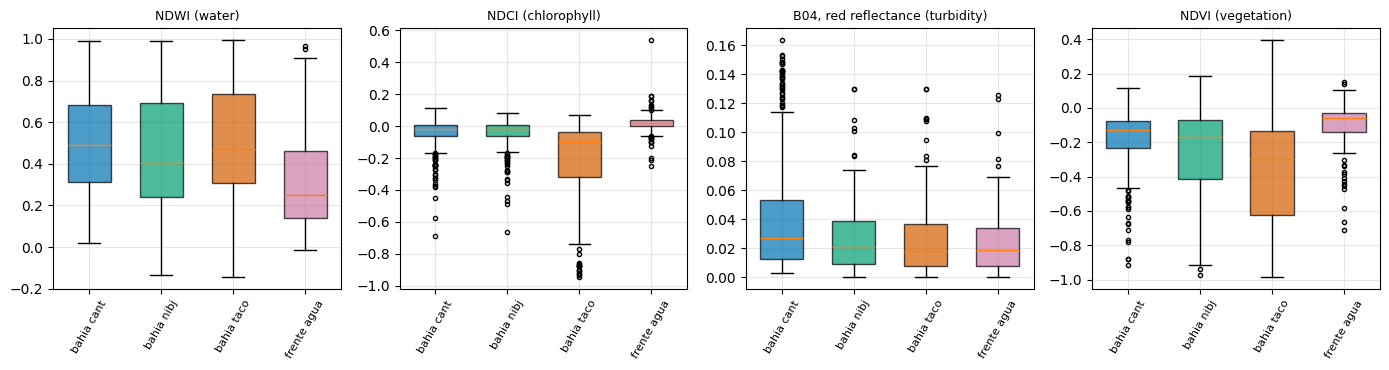

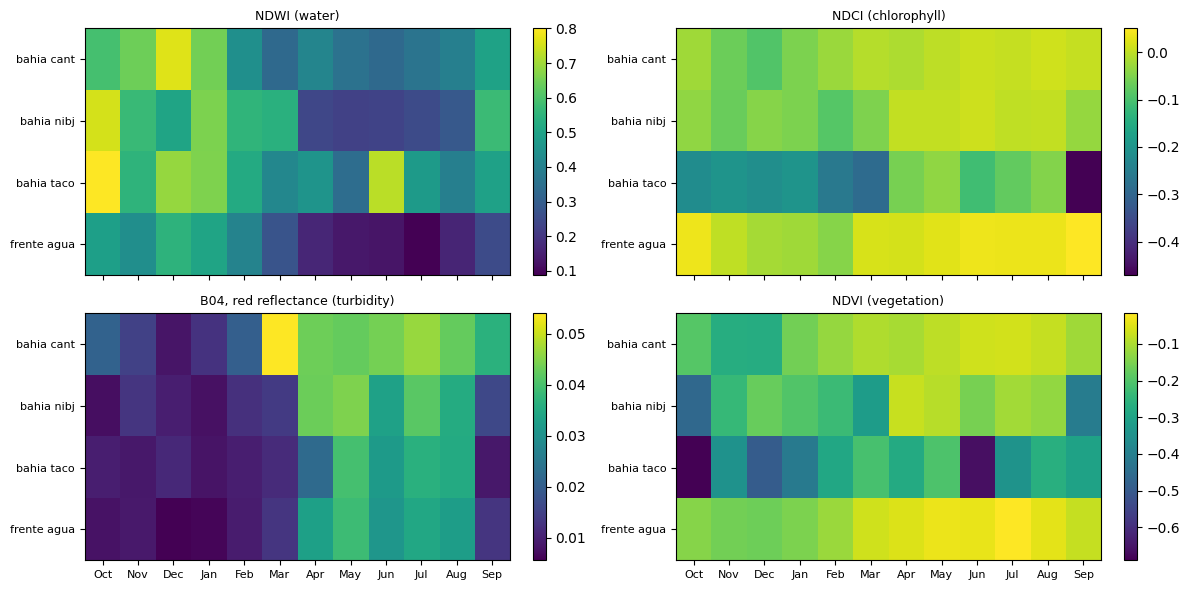

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, variable in zip(axes, LABELS):
    boxes = ax.boxplot([series_of(s2_series, i, variable) for i in ids], tick_labels=[i.replace("_", " ") for i in ids], patch_artist=True,
                     widths=0.6, flierprops={"markersize": 3})
    for patch, identifier in zip(boxes["boxes"], ids):
        patch.set_facecolor(colors[identifier])
        patch.set_alpha(0.7)
    ax.set_title(LABELS[variable], fontsize=9)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout()
fig.savefig(OUTPUTS / "sentinel2_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

first_month = pd.Timestamp(DATES_S2[0]).month
months = [(first_month - 1 + k) % 12 + 1 for k in range(12)]
fig, axes = plt.subplots(2, 2, figsize=(12, 2 + 0.5 * len(ids) * 2), sharex=True)
for ax, variable in zip(axes.ravel(), LABELS):
    monthly = s2_series.groupby(["id", s2_series["date"].dt.month])[variable].median().unstack().reindex(index=ids, columns=months)
    image = ax.imshow(monthly.values, aspect="auto", cmap="viridis")
    ax.set_yticks(range(len(ids)), labels=[i.replace("_", " ") for i in ids], fontsize=8)
    ax.set_xticks(range(12), labels=[MONTHS[m - 1] for m in months], fontsize=8)
    ax.set_title(LABELS[variable], fontsize=9)
    ax.grid(False)
    plt.colorbar(image, ax=ax, fraction=0.04)
plt.tight_layout()
fig.savefig(OUTPUTS / "sentinel2_seasonal_cycle.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Sentinel-2 series: z-score anomalies (plot)

`z = (value - mean) / std` over the whole series; |z| > 2 is unusual. With one year this mixes season and anomaly, so check the image before calling an unusual date an event. The table shows the scene cloud cover and the valid fraction of the window on those dates.

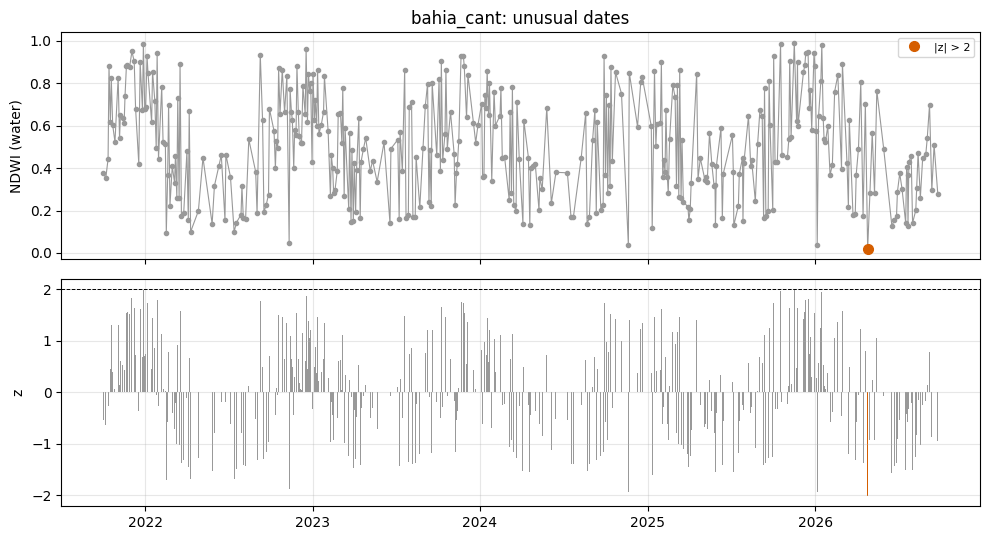

,date,ndwi,cloud_scene,valid_pixels,z
507,2026-04-25 15:36:19.024,0.019,29.4,0.9,-2.0


In [22]:
point_series = series_of(s2_series, POINT, VARIABLE)
z = (point_series - point_series.mean()) / point_series.std()
unusual = z[z.abs() > 2]

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(point_series.index, point_series, "o-", color="0.6", ms=3, lw=0.8)
axes[0].plot(unusual.index, point_series[unusual.index], "o", color="#D55E00", ms=7, label="|z| > 2")
axes[0].set_ylabel(LABELS[VARIABLE])
axes[0].legend(fontsize=8)
axes[0].set_title(f"{POINT}: unusual dates")
axes[1].bar(z.index, z, width=2, color=np.where(z.abs() > 2, "#D55E00", "0.6"))
axes[1].axhline(2, color="k", lw=0.7, ls="--")
axes[1].set_ylabel("z")
plt.tight_layout()
fig.savefig(OUTPUTS / "sentinel2_zscore.png", dpi=150, bbox_inches="tight")
plt.show()

review = s2_series[(s2_series["id"] == POINT) & s2_series["date"].isin(unusual.index)][["date", VARIABLE, "cloud_scene", "valid_pixels"]]
review.assign(z=unusual.values).round({VARIABLE: 3, "cloud_scene": 1, "valid_pixels": 2, "z": 1})

## 18. Interactive plot (save as HTML)

Zoom with the mouse wheel, exact values on hover and click on the legend to hide a point. The hover box shows data quality: scene cloud cover and valid fraction of the window. The HTML file opens in any browser without Python.

In [23]:
interactive_plot = s2_series.hvplot.line(x="date", y=VARIABLE, by="id", width=900, height=380, xlabel="Date", ylabel=LABELS[VARIABLE],
                                         title=f"{LABELS[VARIABLE]} by point", legend="right", hover_cols=["cloud_scene", "valid_pixels"])
hvplot.save(interactive_plot, str(OUTPUTS / "interactive_series.html"))
interactive_plot

:NdOverlay   [id]
   :Curve   [date]   (ndwi,cloud_scene,valid_pixels)

## 19. Interactive map: functions

In [24]:
def summary_html(identifier):
    sub = s2_series[s2_series["id"] == identifier]
    rows = "".join(f"<tr><td>{v.upper()}</td><td>{sub[v].median():.3f}</td><td>{sub[v].quantile(0.1):.3f}</td><td>{sub[v].quantile(0.9):.3f}</td></tr>" for v in LABELS)
    return (f"<table style='font-size:12px'><tr><th>variable</th><th>median</th><th>p10</th><th>p90</th></tr>{rows}</table>"
            f"<p style='font-size:12px'>{sub['ndwi'].notna().sum()} valid dates out of {len(sub)} with an image</p>")


def thumbnail_png(identifier, variable):
    s = series_of(s2_series, identifier, variable)
    fig, ax = plt.subplots(figsize=(3.4, 1.4))
    ax.plot(s.index, s.values, marker="o", ms=2, lw=0.8, color=colors[identifier])
    ax.set_title(f"{variable.upper()} over time", fontsize=8)
    ax.tick_params(labelsize=6)
    memory = io.BytesIO()
    fig.savefig(memory, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(memory.getvalue()).decode()

## 20. Interactive map: build and save

Each point is a marker whose popup summarizes its series: statistics and a small plot (a PNG embedded in the HTML). The circle is the extraction window and the rectangle is the area of the Sentinel-2 scene.

In [25]:
points_map = folium.Map(tiles=None)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(points_map)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri, Maxar, Earthstar Geographics", name="Satellite imagery (Esri)").add_to(points_map)
for p in points[points["id"].isin(ids)].itertuples():
    html = (f"<b>{p.name}</b><br>type: {p.type}<br>{summary_html(p.id)}"
            f"<img src='data:image/png;base64,{thumbnail_png(p.id, VARIABLE)}' width='290'>")
    folium.CircleMarker([p.lat, p.lon], radius=8, color="white", weight=2, fill=True, fill_color=colors[p.id], fill_opacity=0.95, tooltip=p.name,
                        popup=folium.Popup(folium.IFrame(html, width=330, height=330), max_width=340)).add_to(points_map)
    folium.Circle([p.lat, p.lon], radius=RADIUS_S2, color=colors[p.id], weight=1, fill=False).add_to(points_map)
folium.Rectangle([[AREA[1], AREA[0]], [AREA[3], AREA[2]]], color="black", weight=1, fill=False, tooltip="AREA").add_to(points_map)
folium.LayerControl().add_to(points_map)
points_map.fit_bounds([[min(points["lat"].min(), AREA[1]), min(points["lon"].min(), AREA[0])],
                       [max(points["lat"].max(), AREA[3]), max(points["lon"].max(), AREA[2])]])
points_map.save(str(OUTPUTS / "points_map.html"))
points_map

## 21. Landsat: functions

Landsat data arrive as integers (DN) and must be **calibrated**. All bands of a scene are calibrated in one expression with a gain and an offset per band:

| Variable | Band | Calibration |
|---|---|---|
| Surface temperature | `lwir11` | kelvin = DN x 0.00341802 + 149.0; deg C = kelvin - 273.15 |
| Reflectance (green, red, NIR, SWIR1) | `green`, `red`, `nir08`, `swir16` | reflectance = DN x 0.0000275 - 0.2 |

A DN of 0 is "no data". The quality mask uses `qa_pixel` (fill, dilated cloud, cirrus, cloud and shadow) and `qa_radsat` (saturation). The thermal band measures the **skin temperature of the surface** (not the water below it), with errors of 1 K or more: it is not an oceanographic product.

In [26]:
# band: (gain, offset, minimum, maximum) already in the final unit; the offset of lwir11 includes the 273.15 of the conversion to deg C
LANDSAT_CALIBRATION = {"lwir11": (0.00341802, 149.0 - 273.15, -43.15, 66.85),  # outside -43 to 67 deg C it is an error, not a temperature
                       "green": (0.0000275, -0.2, 0, 1), "red": (0.0000275, -0.2, 0, 1),
                       "nir08": (0.0000275, -0.2, 0, 1), "swir16": (0.0000275, -0.2, 0, 1)}  # a valid reflectance is between 0 and 1
LANDSAT_NAMES = {"lwir11": "st_c", "green": "green", "red": "red", "nir08": "nir", "swir16": "swir1"}
QA_BITS = (0, 1, 2, 3, 4)  # fill, dilated cloud, cirrus, cloud, cloud shadow
RADSAT_BITS = (0, 1, 2, 3, 4, 5, 6, 11)  # saturation of the optical bands and terrain occlusion
LANDSAT_VARIABLES = ["st_c", "green", "red", "nir", "swir1", "ndwi", "ndvi"]


def search_landsat(bbox, dates, max_cloud):
    """One search per year (if one fails you do not lose everything). Platforms are filtered: the collection also has Landsat 4, 5 and 7."""
    items = []
    for year in range(int(dates[0][:4]), int(dates[1][:4]) + 1):
        period = (max(dates[0], f"{year}-01-01"), min(dates[1], f"{year}-12-31"))
        items += search_stac("landsat-c2-l2", bbox, period, max_cloud, platforms=["landsat-8", "landsat-9"])
    return items


def add_landsat_attributes(data, items):
    """Platform and scene cloud cover of each date: the items less than one hour away from it."""
    hours = np.array([np.datetime64(i.datetime.replace(tzinfo=None), "ns") for i in items])
    platforms = np.array([i.properties["platform"] for i in items])
    clouds = np.array([i.properties["eo:cloud_cover"] for i in items], dtype=float)
    near = [np.abs(hours - t) < np.timedelta64(1, "h") for t in data["time"].values.astype("datetime64[ns]")]
    return data.assign_coords(platform=("time", [platforms[n][0] for n in near]), cloud_scene=("time", [clouds[n].mean() for n in near]))


def load_landsat(items, bbox, crs, resolution=30, bands=("lwir11", "green", "red", "nir08", "swir16", "qa_pixel", "qa_radsat"), chunk=512):
    """Lazy (dask) cube of DN. `fail_on_error=False` skips the damaged files that Planetary Computer sometimes delivers."""
    cube = odc.stac.load(items, bands=list(bands), crs=crs, resolution=resolution, bbox=bbox, chunks={"x": chunk, "y": chunk},
                         groupby="solar_day", patch_url=planetary_computer.sign, fail_on_error=False)
    return add_landsat_attributes(cube, items)


def landsat_products(cube):
    """Whole cube at once: quality mask, then all the loaded bands calibrated in a single (band, time, y, x) array.

    Returns a Dataset with the calibrated variables (st_c in deg C, reflectance, NDWI, NDVI) and the `valid` and `covered` layers."""
    qa = cube["qa_pixel"].fillna(1).astype("uint16")
    radsat = cube["qa_radsat"].fillna(1).astype("uint16")
    covered = (qa & 1) == 0
    valid = ((qa & sum(1 << b for b in QA_BITS)) == 0) & ((radsat & sum(1 << b for b in RADSAT_BITS)) == 0)

    bands = [b for b in LANDSAT_CALIBRATION if b in cube]
    gain, offset, low, high = (xr.DataArray([LANDSAT_CALIBRATION[b][k] for b in bands], dims="band", coords={"band": bands}) for k in range(4))
    dn = cube[bands].to_array("band")  # one object with all the bands
    values = (dn.where(dn != 0) * gain + offset)  # DN 0 = no data
    values = values.where((values >= low) & (values <= high) & valid)
    products = values.to_dataset("band").rename({b: LANDSAT_NAMES[b] for b in bands})
    if {"green", "nir", "red"} <= set(products):
        products["ndwi"] = normalized_difference(products["green"], products["nir"])
        products["ndvi"] = normalized_difference(products["nir"], products["red"])
    products["valid"], products["covered"] = valid.astype("float32"), covered.astype("float32")
    return products.assign_coords(platform=cube["platform"], cloud_scene=cube["cloud_scene"])

## 22. Landsat: search

Landsat passes every 8 days with both satellites, but clouds erase many dates (about 10 to 25 useful observations per year) and the thermal band is 100 m.

In [27]:
landsat_items = search_landsat(points_bbox(points, RADIUS_LANDSAT), DATES_LANDSAT, MAX_CLOUD_LANDSAT)
print(f"{len(landsat_items)} Landsat 8/9 scenes between {DATES_LANDSAT[0]} and {DATES_LANDSAT[1]} (scene clouds < {MAX_CLOUD_LANDSAT} %)")

778 Landsat 8/9 scenes between 2013-03-01 and 2026-09-30 (scene clouds < 90 %)


In [28]:
from collections import Counter
need = ["lwir11", "green", "red", "nir08", "swir16", "qa_pixel", "qa_radsat"]
print("Escenas encontradas:", len(landsat_items))
print("Por plataforma:", Counter(i.properties["platform"] for i in landsat_items))
for b in need:
    print(f"{b:10s} presente en {sum(b in i.assets for i in landsat_items)} escenas")
sin_st = [i for i in landsat_items if "lwir11" not in i.assets]
if sin_st:
    print("Ejemplo sin lwir11:", sin_st[0].id, sorted(sin_st[0].assets)[:20])

Escenas encontradas: 778
Por plataforma: Counter({'landsat-8': 579, 'landsat-9': 199})
lwir11     presente en 778 escenas
green      presente en 778 escenas
red        presente en 778 escenas
nir08      presente en 778 escenas
swir16     presente en 778 escenas
qa_pixel   presente en 778 escenas
qa_radsat  presente en 778 escenas


## 23. Landsat: load and transform (prepare)

One lazy cube per point and year (only the images that touch its window), already calibrated and masked. Nothing is read yet. The series is the slow part: each year is saved when it finishes and the full result is reused (`REUSE`), so if it stops you can run it again and it continues where it was. The fingerprint summarizes what defines the series: if you change nothing, the saved files are reused.

In [29]:
fingerprint = hashlib.md5(json.dumps([points[["id", "lat", "lon", "type"]].values.tolist(), DATES_LANDSAT, RADIUS_LANDSAT, MIN_FRACTION, MAX_CLOUD_LANDSAT],
                                     default=str).encode()).hexdigest()[:10]
landsat_path = OUTPUTS / "landsat_series.parquet"
cache_dir = OUTPUTS / "landsat_cache"
cache_dir.mkdir(exist_ok=True)
years = range(int(DATES_LANDSAT[0][:4]), int(DATES_LANDSAT[1][:4]) + 1)
reuse_all = REUSE and landsat_path.exists() and read_metadata(landsat_path).get("fingerprint") == fingerprint

landsat_by_year = {}  # lazy products of the years that are not saved yet
if not reuse_all:
    for year in years:
        year_items = [i for i in landsat_items if i.datetime.year == year]
        if year_items and not (REUSE and (cache_dir / f"{fingerprint}_{year}.parquet").exists()):
            landsat_by_year[year] = lazy_windows(year_items, points, RADIUS_LANDSAT, load_landsat, landsat_products)
print("Reusing the saved series" if reuse_all else f"Years to read: {list(landsat_by_year) or 'none (all saved)'}")

Years to read: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


## 24. Landsat: extract values at the points

Median of each variable in the circle of `RADIUS_LANDSAT` meters around each point. Only those windows are read, all points of a year in one parallel pass.

In [30]:
if reuse_all:
    landsat_series = pd.read_parquet(landsat_path)
    print(f"Reused {landsat_path}: {len(landsat_series)} rows")
else:
    t0 = time.time()
    parts = []
    for year in years:
        year_file = cache_dir / f"{fingerprint}_{year}.parquet"
        if year in landsat_by_year:
            year_table = summarize_windows(landsat_by_year[year], points, RADIUS_LANDSAT, MIN_FRACTION, keep=["platform", "cloud_scene"])
            year_table.to_parquet(year_file)
            print(f"{year}: {len(year_table)} rows ({time.time() - t0:.0f} s)")
        elif year_file.exists() and REUSE:
            year_table = pd.read_parquet(year_file)
            print(f"{year}: reused")
        else:
            continue  # a year without scenes
        parts.append(year_table)
    landsat_series = pd.concat(parts, ignore_index=True).merge(points, on="id")
    landsat_series["date"] = landsat_series["date"].dt.normalize()  # only the day matters: the time of the acquisition is dropped
    landsat_series = landsat_series[["id", "name", "type", "lat", "lon", "date", "platform", *LANDSAT_VARIABLES, "cloud_scene", "valid_pixels",
                                     "n_pixels"]].sort_values(["id", "date"]).reset_index(drop=True)
print(f"{len(landsat_series)} rows, {landsat_series['id'].nunique()} points")

2013: 98 rows (33 s)
2014: 154 rows (85 s)
2015: 152 rows (134 s)
2016: 159 rows (186 s)
2017: 155 rows (242 s)
2018: 168 rows (303 s)
2019: 167 rows (356 s)
2020: 159 rows (409 s)
2021: 165 rows (468 s)


2022: 262 rows (557 s)
2023: 288 rows (652 s)
2024: 299 rows (741 s)
2025: 302 rows (842 s)
2026: 233 rows (914 s)
2761 rows, 4 points


## 25. Landsat: save with metadata

In [31]:
if not reuse_all:
    save_parquet(landsat_series, landsat_path, {
        "title": f"Landsat 8 and 9 time series at {len(points)} points ({DATES_LANDSAT[0]} to {DATES_LANDSAT[1]})",
        "description": (f"Median, in a circular window of {RADIUS_LANDSAT} m radius around each point, of the surface temperature (thermal band lwir11), "
                        "of the green, red, NIR and SWIR1 reflectance and of the McFeeters NDWI and the NDVI of Landsat 8/9 Collection 2 Level-2. "
                        "Calibration: temperature (K) = DN x 0.00341802 + 149; reflectance = DN x 0.0000275 - 0.2. Pixels with fill, clouds, shadows, cirrus "
                        f"or saturation are removed before summarizing; dates with less than {MIN_FRACTION:.0%} of the window valid have the variables as NaN."),
        "source": "USGS Landsat 8 and 9 Collection 2 Level-2, read as COG from Microsoft Planetary Computer (collection landsat-c2-l2)",
        "license": "Public domain (USGS Landsat data). Cite: Landsat Collection 2 Level-2, courtesy of the U.S. Geological Survey.",
        "period": f"{DATES_LANDSAT[0]} to {DATES_LANDSAT[1]}", "generated": date.today().isoformat(), "fingerprint": fingerprint,
        "parameters": {"max_scene_cloud": MAX_CLOUD_LANDSAT, "radius_m": RADIUS_LANDSAT, "statistic": "median", "min_valid_fraction": MIN_FRACTION,
                       "resolution_m": 30, "crs": "UTM of each point", "catalog": "planetary"},
        "columns": {"id": "point identifier", "name": "point name", "type": "cover type", "lat": "latitude, degrees (EPSG:4326)",
                    "lon": "longitude, degrees (EPSG:4326)", "date": "day of the satellite pass", "platform": "landsat-8 or landsat-9",
                    "st_c": "calibrated surface temperature, deg C", "green": "green reflectance (0 to 1)",
                    "red": "red reflectance (0 to 1), rises with turbidity", "nir": "near-infrared reflectance (0 to 1)",
                    "swir1": "shortwave-infrared 1 reflectance (0 to 1)", "ndwi": "(green - NIR) / (green + NIR), positive over water",
                    "ndvi": "(NIR - red) / (NIR + red)", "cloud_scene": "% cloud cover of the whole scene (eo:cloud_cover)",
                    "valid_pixels": "fraction (0 to 1) of the window that passed the quality mask", "n_pixels": "pixels in the window"}})
    print(f"Saved: {landsat_path} ({landsat_path.stat().st_size / 1024:.0f} kB)")
else:
    print("Nothing to save: the series was reused")

Saved: outputs/landsat_series.parquet (98 kB)


In [32]:
print(landsat_series.groupby("id")[["st_c", "red", "ndwi"]].count())
print(landsat_series.groupby("id").size().rename("filas"))

             st_c  red  ndwi
id                          
bahia_cant    380  369   341
bahia_nibj    226  217   225
bahia_taco    360  350   355
frente_agua   423  327   355
id
bahia_cant     778
bahia_nibj     432
bahia_taco     774
frente_agua    777
Name: filas, dtype: int64


## 26. Landsat: quality control over water

The `qa_pixel` mask flags high-confidence clouds; a thin cloud or haze can stay unmarked and be measured as "very cold water". But open water absorbs almost all red and infrared light: an observation over water with **red reflectance above 0.05 or SWIR1 above 0.02** is suspicious and is set to `NaN` (the date is kept). Land is not touched. It is a declared rule: it can let thin haze through and discard an algal bloom.

In [33]:
def control_water_quality(table, red_max=0.05, swir1_max=0.02, types=WATER_TYPES):
    clean = table.copy()
    suspicious = clean["type"].isin(types) & ((clean["red"] > red_max) | (clean["swir1"] > swir1_max))
    clean.loc[suspicious, LANDSAT_VARIABLES] = np.nan
    return clean

In [61]:
CLOUD_MAX = 50   # % máximo de nubes de la escena
ST_MIN = 20      # °C: por debajo se trata como nube o artefacto en agua tropical

tmp = landsat_series.copy()
bad = (tmp["cloud_scene"] > CLOUD_MAX) | (tmp["st_c"] < ST_MIN)
print("Observaciones eliminadas por punto:")
print(tmp[bad].groupby("id").size())
tmp.loc[bad, LANDSAT_VARIABLES] = np.nan
landsat_clean = control_water_quality(tmp)
print(landsat_clean.groupby("id")["st_c"].count())

Observaciones eliminadas por punto:
id
bahia_cant     136
bahia_nibj      75
bahia_taco     137
frente_agua    140
dtype: int64
id
bahia_cant     228
bahia_nibj     127
bahia_taco     211
frente_agua    251
Name: st_c, dtype: int64


## 27. Climatology and episodes: functions

**Climatology with irregular observations (the idea of Hobday, adapted).** Hobday's method needs a daily series and 30 years: Landsat has neither. For each of the 366 days of the year we gather **all the observations of the base period less than 15 days from that day, from all years** (31-day window), compute the mean and the percentiles `PERCENTILE` and `100 - PERCENTILE`, and smooth the curve with a circular 15-day moving average. With fewer than `CLIM_MIN_OBS` observations in the window no climatology is invented. The calendar has 366 days: February 29 is always day 60.

**Episodes.** One loose observation is not an episode: it must **persist**. An episode is **at least `MIN_OBS` consecutive valid observations** above the hot threshold (or below the cold one):

* Dates with clouds (`NaN`) are not observations: they neither break nor extend the streak.
* Between two consecutive observations of the episode at most `MAX_GAP_DAYS` days can pass: a streak **does not cross a long gap**.
* A valid observation that does **not** exceed the threshold breaks the streak.
* It is not a Hobday event: `duration_days` (first to last observation) is only a lower bound, and the table **underestimates** the real frequency.

In [51]:
def day366(index):
    """Day of the year in a 366-day calendar (in non-leap years, from March 1 add 1)."""
    return index.dayofyear.to_numpy() + (~index.is_leap_year & (index.month >= 3)).astype(int)


def smooth(curve, width):
    """Circular moving average that ignores NaN (a day without climatology does not contaminate its neighbors)."""
    half = width // 2
    extended = np.concatenate([curve[-half:], curve, curve[:half]])
    valid = np.isfinite(extended)
    total = np.convolve(np.where(valid, extended, 0.0), np.ones(width), mode="valid")
    n = np.convolve(valid.astype(float), np.ones(width), mode="valid")
    with np.errstate(invalid="ignore"):
        smoothed = total / n
    return np.where(np.isfinite(curve), smoothed, np.nan)


def climatology(series, base=BASE, window=31, smoothing=15, min_obs=CLIM_MIN_OBS, percentile=PERCENTILE):
    """DataFrame indexed by `day` (1 to 366): mean, `high` (percentile), `low` (100 - percentile) and `n` (observations gathered)."""
    s = series.dropna()
    s = s[(s.index.year >= base[0]) & (s.index.year <= base[1])]
    if s.empty:
        raise ValueError(f"The series has no data between {base[0]} and {base[1]}")
    values, day = s.to_numpy(dtype=float), day366(s.index)
    curves = {name: np.full(366, np.nan) for name in ("mean", "high", "low")}
    count = np.zeros(366, dtype=int)
    for d in range(1, 367):
        near = values[np.abs((day - d + 183) % 366 - 183) <= window // 2]  # circular distance: day 366 is a neighbor of day 1
        count[d - 1] = near.size
        if near.size >= min_obs:
            curves["mean"][d - 1] = near.mean()
            curves["high"][d - 1], curves["low"][d - 1] = np.percentile(near, [percentile, 100 - percentile])
    curves = {name: smooth(curve, smoothing) for name, curve in curves.items()}
    return pd.DataFrame({**curves, "n": count}, index=pd.RangeIndex(1, 367, name="day"))


def anomalies(series, clim):
    """Next to each observation: mean and thresholds of its day of the year, the anomaly and whether it exceeds the hot or cold threshold."""
    table = clim.loc[day366(series.index), ["mean", "high", "low"]].set_index(series.index)
    table.insert(0, "value", series.to_numpy(dtype=float))
    table["anomaly"] = table["value"] - table["mean"]
    table["exceeds_hot"] = table["value"] > table["high"]
    table["exceeds_cold"] = table["value"] < table["low"]
    return table


def find_episodes(series, clim, kind="hot", min_obs=MIN_OBS, max_gap=MAX_GAP_DAYS):
    """One row per episode: start, end, duration (days), n_obs, peak day, intensities (deg C) and whether it is still ongoing."""
    s = series.dropna()
    day = day366(s.index)
    anomaly = s.to_numpy() - clim["mean"].loc[day].to_numpy()
    threshold = clim["high" if kind == "hot" else "low"].loc[day].to_numpy()
    evaluable = ~np.isnan(threshold)  # a day without climatology cannot be evaluated
    s, anomaly, threshold = s[evaluable], anomaly[evaluable], threshold[evaluable]
    exceeds = s.to_numpy() > threshold if kind == "hot" else s.to_numpy() < threshold
    streaks, current = [], []
    for i in range(len(s)):
        if exceeds[i] and current and (s.index[i] - s.index[current[-1]]).days <= max_gap:
            current.append(i)  # the streak continues
        else:
            if len(current) >= min_obs:
                streaks.append(current)
            current = [i] if exceeds[i] else []  # a normal value, or a long gap, breaks the streak
    if len(current) >= min_obs:
        streaks.append(current)
    rows = []
    for streak in streaks:
        a = anomaly[streak]
        peak = streak[int(np.argmax(a) if kind == "hot" else np.argmin(a))]
        rows.append({"kind": kind, "start": s.index[streak[0]], "end": s.index[streak[-1]], "duration_days": (s.index[streak[-1]] - s.index[streak[0]]).days + 1,
                     "n_obs": len(streak), "peak_date": s.index[peak], "max_intensity": anomaly[peak], "mean_intensity": a.mean(),
                     "ongoing": streak[-1] == len(s) - 1})
    return pd.DataFrame(rows, columns=["kind", "start", "end", "duration_days", "n_obs", "peak_date", "max_intensity", "mean_intensity", "ongoing"])

## 28. Climatology and episodes: compute for every point

Each point is compared **only with itself**: a 2 deg C anomaly in water is important, on land it is noise.

In [52]:
EPISODE_COLUMNS = ["point", "name", "kind", "start", "end", "duration_days", "n_obs", "peak_date", "max_intensity", "mean_intensity", "ongoing"]
climatologies, parts = {}, []
for p in points.itertuples():
    s = series_of(landsat_clean, p.id, "st_c")
    try:
        climatologies[p.id] = climatology(s)
    except ValueError as error:
        print(f"{p.id}: {error}")
        continue
    for kind in ("hot", "cold"):
        found = find_episodes(s, climatologies[p.id], kind)
        if not found.empty:
            parts.append(found.assign(point=p.id, name=p.name))
episodes_all = (pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=EPISODE_COLUMNS))[EPISODE_COLUMNS]
episodes_all = episodes_all.sort_values(["point", "start"]).reset_index(drop=True)
print(f"{len(episodes_all)} episodes in {episodes_all['point'].nunique()} points")
if not episodes_all.empty:
    for a in episodes_all[episodes_all["ongoing"].astype(bool)].itertuples():
        print(f"Ongoing: {a.name} ({a.kind}), since {a.start.date()}, {a.n_obs} observations. Its duration is provisional: it can grow or end.")
    episodes_summary = episodes_all.groupby(["point", "kind"]).agg(episodes=("start", "size"), max_obs=("n_obs", "max"), max_duration=("duration_days", "max"),
                                                                   max_intensity=("max_intensity", lambda x: x.loc[x.abs().idxmax()])).round(2)
episodes_summary if not episodes_all.empty else None

9 episodes in 4 points


episodes  max_obs  max_duration  max_intensity
point       kind                                                
bahia_cant  cold         3        3            25          -6.18
bahia_nibj  hot          1        2            17           1.44
bahia_taco  cold         1        2             8          -2.28
frente_agua cold         2        3            17          -1.55
            hot          2        2            24           1.41

Observaciones con temperatura: {'frente_agua': 251, 'bahia_cant': 228, 'bahia_taco': 211, 'bahia_nibj': 127} | mejores 3: ['frente_agua', 'bahia_cant', 'bahia_taco']
                  episodios  max_obs  max_dias  max_intensidad
point       kind                                              
bahia_cant  cold          3        3        18           -6.33
bahia_taco  cold          1        2         8           -2.11
frente_agua cold          2        3        17           -1.61
Frente a la Bahía de Yamanigüey: 0 días del año sin climatología


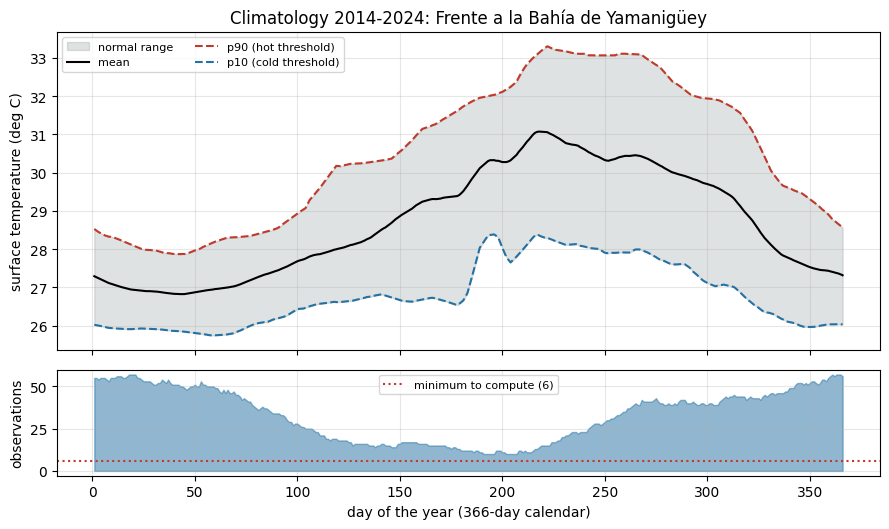

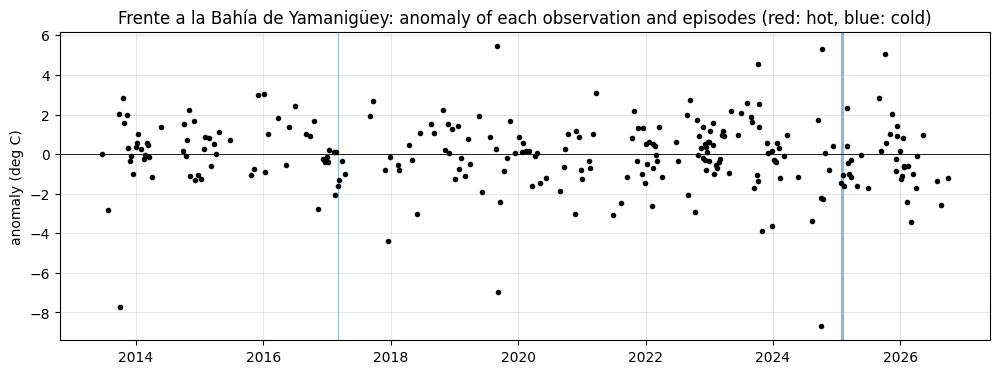

Bahía de Cañete: 0 días del año sin climatología


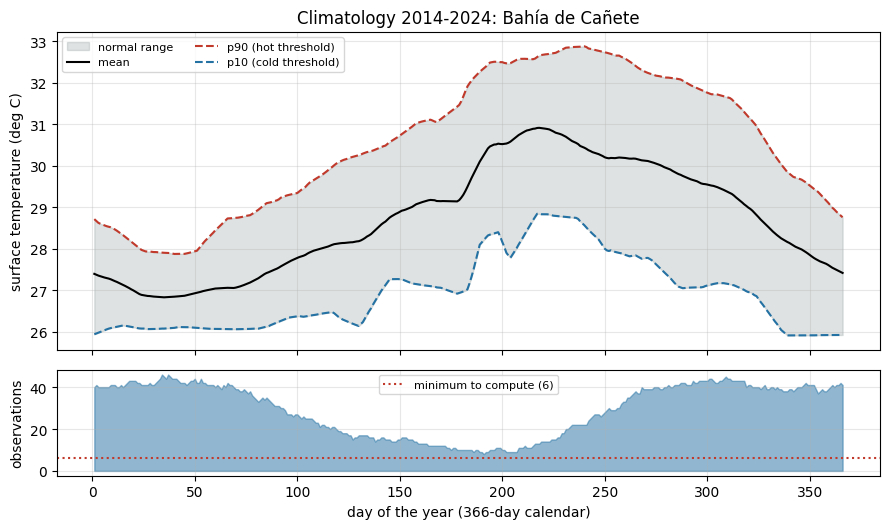

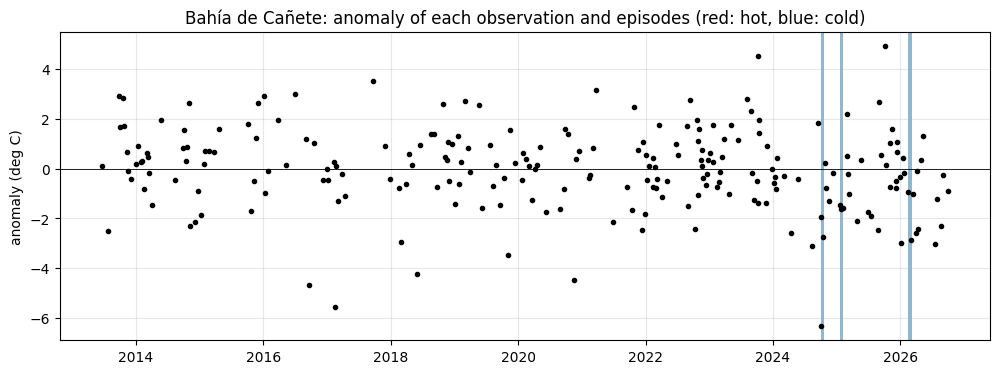

Bahía de Taco: 62 días del año sin climatología


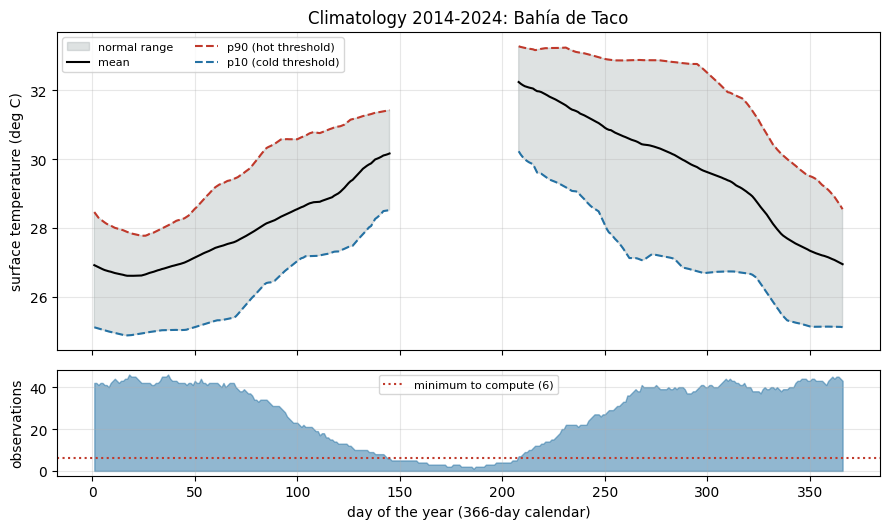

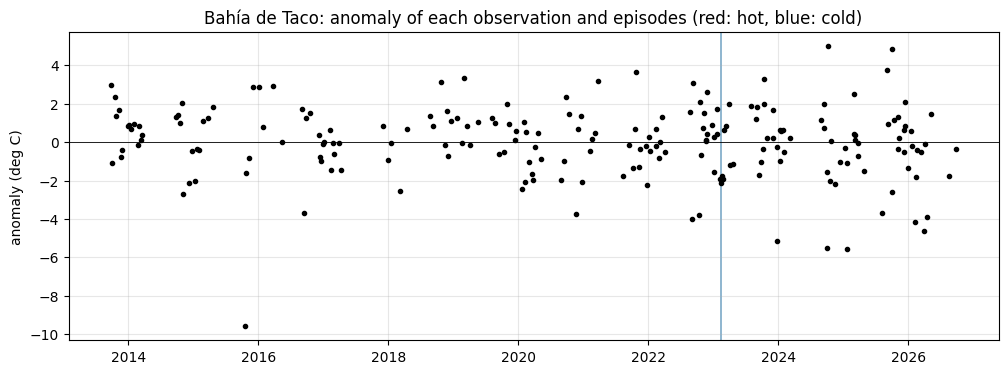

In [62]:
CLIM_WINDOW, CLIM_MIN, EP_MIN_OBS = 61, 6, 2   # ventana (días), mínimo de obs., obs. mínimas por episodio
NAMES = {"bahia_cant": "Bahía de Cañete",
         "bahia_taco": "Bahía de Taco",
         "bahia_nibj": "Nibujón",
         "frente_agua": "Frente a la Bahía de Yamanigüey"}

climatologies, parts = {}, []
for p in points.itertuples():
    s = series_of(landsat_clean, p.id, "st_c")
    climatologies[p.id] = climatology(s, window=CLIM_WINDOW, min_obs=CLIM_MIN)
    for kind in ("hot", "cold"):
        found = find_episodes(s, climatologies[p.id], kind, min_obs=EP_MIN_OBS)
        if not found.empty:
            parts.append(found.assign(point=p.id, name=p.name))
episodes_all = pd.concat(parts, ignore_index=True).sort_values(["point", "start"]).reset_index(drop=True)
episodes_all["name"] = episodes_all["point"].map(NAMES)

counts = landsat_clean.groupby("id")["st_c"].count().sort_values(ascending=False)
best = list(counts.index[:3])
print("Observaciones con temperatura:", counts.to_dict(), "| mejores 3:", best)
print(episodes_all.groupby(["point", "kind"]).agg(episodios=("start", "size"), max_obs=("n_obs", "max"),
      max_dias=("duration_days", "max"), max_intensidad=("max_intensity", lambda x: x.loc[x.abs().idxmax()])).round(2))

for pid in best:
    clim = climatologies[pid]
    print(f"{NAMES[pid]}: {int(clim['mean'].isna().sum())} días del año sin climatología")
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax.fill_between(clim.index, clim["low"], clim["high"], color=GRAY, alpha=0.25, label="normal range")
    ax.plot(clim["mean"], color="black", label="mean")
    ax.plot(clim["high"], color=RED, ls="--", label=f"p{PERCENTILE} (hot threshold)")
    ax.plot(clim["low"], color=BLUE, ls="--", label=f"p{100 - PERCENTILE} (cold threshold)")
    ax.set_ylabel("surface temperature (deg C)")
    ax.set_title(f"Climatology {BASE[0]}-{BASE[1]}: {NAMES[pid]}")
    ax.legend(ncol=2, fontsize=8)
    ax2.fill_between(clim.index, clim["n"], color=BLUE, alpha=0.5)
    ax2.axhline(CLIM_MIN, color=RED, ls=":", label=f"minimum to compute ({CLIM_MIN})")
    ax2.set_xlabel("day of the year (366-day calendar)"); ax2.set_ylabel("observations"); ax2.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(OUTPUTS / f"landsat_climatology_{pid}.png", dpi=150, bbox_inches="tight")
    plt.show()

    s = series_of(landsat_clean, pid, "st_c")
    anom = anomalies(s.dropna(), clim)["anomaly"].dropna()
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(anom.index, anom, "o", ms=3, color="black")
    for ep in episodes_all[episodes_all["point"] == pid].itertuples():
        ax.axvspan(ep.start, ep.end + pd.Timedelta(days=1), color=RED if ep.kind == "hot" else BLUE, alpha=0.5, lw=0)
    ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("anomaly (deg C)")
    ax.set_title(f"{NAMES[pid]}: anomaly of each observation and episodes (red: hot, blue: cold)")
    fig.savefig(OUTPUTS / f"landsat_episodes_{pid}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [53]:
print(s2_series.groupby("id")[["ndwi", "b04"]].count())
print(landsat_clean.groupby("id")[["st_c", "red", "ndwi"]].count())
print(landsat_series.groupby(["id", "platform"]).size().unstack())

             ndwi  b04
id                    
bahia_cant    395  395
bahia_nibj    214  222
bahia_taco    148  213
frente_agua   227  228
             st_c  red  ndwi
id                          
bahia_cant    228  222   191
bahia_nibj    127  119   126
bahia_taco    211  200   205
frente_agua   251  193   201
platform     landsat-8  landsat-9
id                               
bahia_cant         579        199
bahia_nibj         325        107
bahia_taco         576        198
frente_agua        578        199


## 29. Isolation Forest: functions

**Fixed thresholds against machine learning.** The thresholds (p90 and p10) are a **rule-based** method. **Isolation Forest** is an unsupervised outlier detector: it builds many trees with random cuts and unusual points are isolated with few cuts. It does not know the calendar, so we give it **anomalies** (no seasonality), and it can look at **several variables at once**: temperature, red reflectance and NDWI. You set the contamination (`CONTAMINATION`): the fraction of observations you expect to be outliers.

The **Jaccard index** (observations in common / observations in the union) goes from 0 to 1 and measures how much the two methods agree. They answer different questions: the threshold asks whether this temperature is unusual for this time of year; the forest asks whether this combination of anomalies is rare in the whole series.

In [54]:
def anomalies_of(point_table, variables):
    """Anomaly of each variable against its own climatology; only the dates with all variables."""
    return pd.DataFrame({v: anomalies(point_table[v].dropna(), climatology(point_table[v]))["anomaly"] for v in variables}).dropna()


def isolate(anomaly_variables, contamination=CONTAMINATION):
    forest = IsolationForest(n_estimators=200, contamination=contamination, random_state=0).fit(anomaly_variables)
    return pd.Series(forest.predict(anomaly_variables) == -1, index=anomaly_variables.index)


def jaccard(a, b):
    b = b.reindex(a.index, fill_value=False)
    union = int((a | b).sum())
    return int((a & b).sum()) / union if union else np.nan

In [55]:
rows, outliers = [], {}
for p in points.itertuples():
    point_table = landsat_clean[landsat_clean["id"] == p.id].set_index("date")[["st_c", "red", "ndwi"]].astype(float)
    try:
        only_t, three = anomalies_of(point_table, ["st_c"]), anomalies_of(point_table, ["st_c", "red", "ndwi"])
    except ValueError:
        continue
    if len(three) < 20:
        continue
    threshold_anomalies = anomalies(point_table["st_c"].dropna(), climatologies[p.id])
    flagged_threshold = threshold_anomalies["exceeds_hot"] | threshold_anomalies["exceeds_cold"]
    flagged_only_t, flagged_three = isolate(only_t), isolate(three)
    rows.append({"point": p.id, "above threshold": int(flagged_threshold.sum()), "IF temperature only": int(flagged_only_t.sum()), "IF three variables": int(flagged_three.sum()),
                 "Jaccard temperature only": round(jaccard(flagged_threshold, flagged_only_t), 2), "Jaccard three variables": round(jaccard(flagged_threshold, flagged_three), 2)})
    outliers[p.id] = (three, flagged_three)
outlier_table = pd.DataFrame(rows).set_index("point") if rows else pd.DataFrame()
outlier_table.to_csv(OUTPUTS / "landsat_outliers.csv")
outlier_table

,above threshold,IF temperature only,IF three variables,Jaccard temperature only,Jaccard three variables
point,,,,,
bahia_cant,50,21,17,0.42,0.20
bahia_taco,42,20,18,0.48,0.25
bahia_nibj,30,12,11,0.35,0.21
frente_agua,65,24,15,0.35,0.11


## 30. Landsat summary by point

In [56]:
landsat_summary = landsat_clean.groupby(["id", "type"]).agg(st_median=("st_c", "median"), st_p5=("st_c", lambda s: s.quantile(0.05)),
                                                            st_p95=("st_c", lambda s: s.quantile(0.95)), ndwi=("ndwi", "median"), ndvi=("ndvi", "median"),
                                                            red=("red", "median")).round(3)
landsat_summary["range_p95_p5"] = (landsat_summary["st_p95"] - landsat_summary["st_p5"]).round(1)
landsat_summary.to_csv(OUTPUTS / "landsat_summary.csv")
landsat_summary.sort_values("st_median")

,,st_median,st_p5,st_p95,ndwi,ndvi,red,range_p95_p5
id,type,,,,,,,
frente_agua,mar,27.807,25.524,32.353,0.681,0.511,0.001,6.8
bahia_cant,bahia,28.041,25.422,32.159,0.895,-0.122,0.002,6.7
bahia_taco,bahia,28.172,24.835,32.823,0.640,0.470,0.002,8.0
bahia_nibj,bahia,28.492,26.126,33.060,0.644,0.669,0.001,6.9


## 31. Landsat: climatology and episodes (plot)

For `POINT`: the climatology with its thresholds and the number of observations behind it, then the anomaly of each observation with the episodes (red: hot, blue: cold) and the Isolation Forest outliers (orange circles).

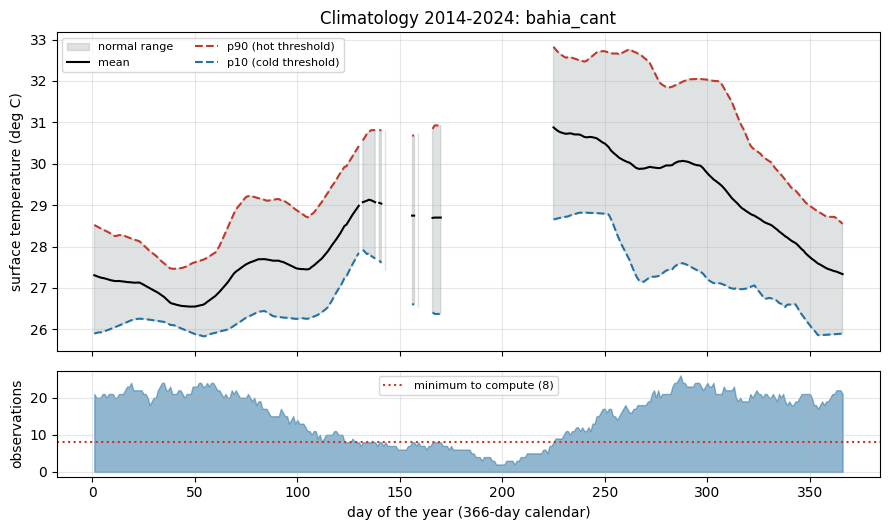

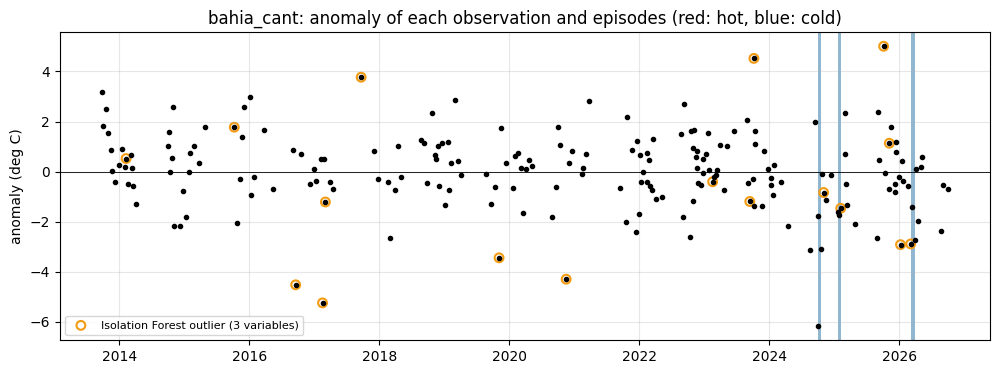

In [57]:
clim = climatologies[POINT]
point_st = series_of(landsat_clean, POINT, "st_c")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.fill_between(clim.index, clim["low"], clim["high"], color=GRAY, alpha=0.25, label="normal range")
ax.plot(clim["mean"], color="black", label="mean")
ax.plot(clim["high"], color=RED, ls="--", label=f"p{PERCENTILE} (hot threshold)")
ax.plot(clim["low"], color=BLUE, ls="--", label=f"p{100 - PERCENTILE} (cold threshold)")
ax.set_ylabel("surface temperature (deg C)")
ax.set_title(f"Climatology {BASE[0]}-{BASE[1]}: {POINT}")
ax.legend(ncol=2, fontsize=8)
ax2.fill_between(clim.index, clim["n"], color=BLUE, alpha=0.5)
ax2.axhline(CLIM_MIN_OBS, color=RED, ls=":", label=f"minimum to compute ({CLIM_MIN_OBS})")
ax2.set_xlabel("day of the year (366-day calendar)")
ax2.set_ylabel("observations")
ax2.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUTS / "landsat_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

point_anomaly = anomalies(point_st, clim)["anomaly"].dropna()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(point_anomaly.index, point_anomaly, "o", ms=3, color="black")
for ep in episodes_all[episodes_all["point"] == POINT].itertuples():
    ax.axvspan(ep.start, ep.end + pd.Timedelta(days=1), color=RED if ep.kind == "hot" else BLUE, alpha=0.5, lw=0)
if POINT in outliers:
    three, flagged = outliers[POINT]
    ax.scatter(three.index[flagged.to_numpy()], three.loc[flagged.to_numpy(), "st_c"], s=40, facecolors="none", edgecolors="#f39c12", lw=1.5,
               label="Isolation Forest outlier (3 variables)")
    ax.legend(loc="lower left", fontsize=8)
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("anomaly (deg C)")
ax.set_title(f"{POINT}: anomaly of each observation and episodes (red: hot, blue: cold)")
fig.savefig(OUTPUTS / "landsat_episodes.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
pid = "bahia_cant"
s = series_of(landsat_clean, pid, "st_c").dropna()
a = anomalies(s, climatologies[pid]).dropna(subset=["anomaly"])
cols = ["platform", "cloud_scene", "valid_pixels", "red", "swir1", "ndwi"]
extra = landsat_clean[landsat_clean["id"] == pid].set_index("date")[cols]
print(a[a["anomaly"] < -4][["value", "anomaly"]].join(extra).round(3).to_string())

             value  anomaly   platform  cloud_scene  valid_pixels    red  swir1   ndwi
date                                                                                  
2016-09-17  25.518   -4.524  landsat-8        12.37         1.000  0.001  0.013  0.977
2017-02-15  21.307   -4.940  landsat-8         2.33         1.000  0.002  0.015  0.638
2020-02-08  19.906   -6.433  landsat-8        13.76         1.000  0.003  0.010  0.583
2020-11-15  24.525   -4.446  landsat-8        29.20         0.795  0.014  0.015  0.746
2024-10-01  23.720   -6.181  landsat-9        27.67         1.000    NaN  0.004  0.947
2025-02-21  18.704   -7.635  landsat-8        57.26         1.000  0.002  0.019  0.475
2025-09-26  15.097  -14.798  landsat-8        64.04         1.000    NaN  0.015  0.540


## 32. Save the episodes

The episodes are a derived dataset: if we do not save them with their documentation, nobody will know which parameters produced them.

In [44]:
episodes_path = OUTPUTS / "landsat_episodes.parquet"
save_parquet(episodes_all, episodes_path, {
    "title": f"Hot and cold episodes of the surface temperature at {points['id'].nunique()} points (Landsat 8 and 9, {DATES_LANDSAT[0]} to {DATES_LANDSAT[1]})",
    "source": "USGS Landsat 8 and 9 Collection 2 Level-2 (thermal band lwir11) read from Microsoft Planetary Computer",
    "license": "Public domain (USGS data)",
    "period": f"{DATES_LANDSAT[0]} to {DATES_LANDSAT[1]}", "generated": date.today().isoformat(),
    "method": "Anomalies against a climatology by day window; inspired by Hobday et al. 2016, but not a marine heatwave: Landsat does not give a daily series",
    "parameters": {"base": list(BASE), "window_days": 31, "smoothing_days": 15, "hot_percentile": PERCENTILE, "cold_percentile": 100 - PERCENTILE,
                   "min_observations_per_window": CLIM_MIN_OBS, "min_consecutive_observations": MIN_OBS, "max_gap_days": MAX_GAP_DAYS,
                   "quality_control": f"points of type {WATER_TYPES} with red reflectance above 0.05 or SWIR1 above 0.02: discarded"},
    "limitations": "Landsat passes every 8 days and clouds erase many dates: the duration of an episode is a lower bound and the table underestimates the real frequency. "
                   "The thermal band has 100 m native resolution and measures the skin temperature of the surface (errors of 1 K or more).",
    "columns": {"point": "point id", "name": "point name", "kind": "hot or cold", "start": "date of the first observation of the episode",
                "end": "date of the last observation", "duration_days": "days from the first to the last observation, both included (lower bound)",
                "n_obs": "consecutive valid observations of the episode", "peak_date": "date of the largest anomaly",
                "max_intensity": "deg C above the climatological mean (negative for cold)", "mean_intensity": "deg C",
                "ongoing": "True if it ends at the last valid observation of the series"}})
print(f"Saved: {episodes_path} ({len(episodes_all)} episodes)")

Saved: outputs/landsat_episodes.parquet (9 episodes)


## 33. Grid of 500 m (optional): functions

Until now we looked at points; Landsat gives images. We load the temperature **every 500 m** (a pixel sample, no averaging) and repeat the climatology **in every pixel**. By construction, about 10 % of the observations of the base period are above the p90. If you look only at the last years, a fraction much larger than 0.10 means pixels warmer than normal. With few observations per pixel the fraction is noisy: look at spatial patterns, not at single pixels. Set `RUN_GRID = True` in the configuration to run it.

In [45]:
def load_grid(area, dates, resolution, min_valid=0.10):
    """Surface temperature (time, y, x) of all dates with at least `min_valid` of valid pixels. Same load and transform as the points."""
    crs = utm_crs((area[0] + area[2]) / 2, (area[1] + area[3]) / 2)
    items = search_landsat(area, dates, MAX_CLOUD_LANDSAT)
    slices = []
    for year in sorted({i.datetime.year for i in items}):
        cube = load_landsat([i for i in items if i.datetime.year == year], area, crs, resolution, bands=("lwir11", "qa_pixel", "qa_radsat"))
        products = landsat_products(cube).compute(scheduler="threads", num_workers=32)
        useful = (products["covered"].mean(("x", "y")) > 0.05) & (products["st_c"].notnull().mean(("x", "y")) >= min_valid)
        slices.append(products["st_c"].where(useful, drop=True).astype("float32"))
        print(f"{year}: {int(useful.sum())} useful dates")
    return xr.concat(slices, dim="time").sortby("time")


def grid_climatology(grid, base=BASE, window=31, step=16, min_obs=CLIM_MIN_OBS, percentile=PERCENTILE):
    """Climatology by day window in every pixel, evaluated every `step` days of the year (the curve is smooth)."""
    time_index = pd.DatetimeIndex(grid["time"].values)
    in_base = (time_index.year >= base[0]) & (time_index.year <= base[1])
    values, day = grid.isel(time=np.flatnonzero(in_base)).to_numpy(), day366(time_index[in_base])
    centers = np.arange(1, 367, step)
    out = {name: np.full((len(centers), *values.shape[1:]), np.nan, dtype="float32") for name in ("mean", "high", "low")}
    for k, center in enumerate(centers):
        together = values[np.abs((day - center + 183) % 366 - 183) <= window // 2]
        if together.shape[0] == 0:
            continue
        enough = np.isfinite(together).sum(axis=0) >= min_obs
        high, low = np.nanpercentile(together, [percentile, 100 - percentile], axis=0)
        for name, value in (("mean", np.nanmean(together, axis=0)), ("high", high), ("low", low)):
            out[name][k] = np.where(enough, value, np.nan)
    return xr.Dataset({n: (("center", "y", "x"), v) for n, v in out.items()}, coords={"center": centers, "y": grid["y"].values, "x": grid["x"].values})


def anomaly_frequency(grid, clim, kind="hot", period=GRID_YEARS):
    """Fraction of valid observations above the hot threshold (or below the cold one) in every pixel, within `period`."""
    time_index = pd.DatetimeIndex(grid["time"].values)
    chosen = np.flatnonzero((time_index.year >= period[0]) & (time_index.year <= period[1]))
    sub = grid.isel(time=chosen)
    center = np.abs((day366(time_index[chosen])[:, None] - clim["center"].values[None, :] + 183) % 366 - 183).argmin(axis=1)  # nearest center
    threshold = clim["high" if kind == "hot" else "low"].isel(center=xr.DataArray(center, dims="time")).assign_coords(time=sub["time"])
    has_data = sub.notnull() & threshold.notnull()
    exceeds = (sub > threshold) if kind == "hot" else (sub < threshold)
    n_obs = has_data.sum("time")
    return (exceeds & has_data).sum("time") / n_obs.where(n_obs > 0), n_obs

## 34. Grid of 500 m (optional): prepare and compute

In [46]:
if RUN_GRID:
    t0 = time.time()
    grid_raw = load_grid(GRID_AREA, DATES_LANDSAT, GRID_RESOLUTION)
    too_cold = float((grid_raw < GRID_T_MIN).sum() / grid_raw.notnull().sum())
    print(f"{grid_raw.sizes['time']} dates, {grid_raw.sizes['y']} x {grid_raw.sizes['x']} pixels ({time.time() - t0:.0f} s)")
    print(f"{too_cold:.1%} of the values are below {GRID_T_MIN} deg C: discarded (almost all unmarked clouds)")
    grid = grid_raw.where(grid_raw >= GRID_T_MIN)  # declared control, without reflectance (the grid only keeps the thermal band)

    grid_clim = grid_climatology(grid)
    freq_hot, n_hot = anomaly_frequency(grid, grid_clim, "hot")
    freq_cold, _ = anomaly_frequency(grid, grid_clim, "cold")
    print(f"Observations per pixel in {GRID_YEARS[0]}-{GRID_YEARS[1]}: median {int(n_hot.median())}")
    print(f"Fraction above the hot threshold: median {float(freq_hot.median()):.2f} | below the cold one: {float(freq_cold.median()):.2f} (expected {1 - PERCENTILE / 100:.2f})")
else:
    print("Grid skipped (RUN_GRID = False)")

Grid skipped (RUN_GRID = False)


## 35. Grid of 500 m (optional): plot

In [47]:
if RUN_GRID:
    grid_crs = utm_crs((GRID_AREA[0] + GRID_AREA[2]) / 2, (GRID_AREA[1] + GRID_AREA[3]) / 2)
    x_km, y_km = grid["x"] / 1000, grid["y"] / 1000
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
    for ax, layer, title, cmap, vmax in ((axes[0], grid.notnull().sum("time"), "Valid observations per pixel", "viridis", None),
                                         (axes[1], freq_hot, f"Fraction above p{PERCENTILE}, {GRID_YEARS[0]}-{GRID_YEARS[1]}", "Reds", 0.5),
                                         (axes[2], freq_cold, f"Fraction below p{100 - PERCENTILE}, {GRID_YEARS[0]}-{GRID_YEARS[1]}", "Blues", 0.5)):
        image = ax.pcolormesh(x_km, y_km, layer, cmap=cmap, vmin=0, vmax=vmax, shading="nearest")
        for p in points.itertuples():
            px, py = to_utm(p.lon, p.lat, grid_crs)
            ax.plot(px / 1000, py / 1000, "k^", ms=5, mec="white")
        ax.set_title(title)
        ax.set_xlabel("east (km)")
        ax.set_aspect("equal")
        plt.colorbar(image, ax=ax, shrink=0.75)
    axes[0].set_ylabel("north (km)")
    plt.tight_layout()
    fig.savefig(OUTPUTS / "grid_anomaly_frequency.png", dpi=150, bbox_inches="tight")
    plt.show()

## 36. Saved outputs

In [48]:
for file in sorted(OUTPUTS.iterdir()):
    if file.is_file():
        print(f"{file.name:34s} {file.stat().st_size / 1024:8.0f} kB")

interactive_series.html                  80 kB
landsat_climatology.png                 137 kB
landsat_episodes.parquet                 11 kB
landsat_episodes.png                     65 kB
landsat_outliers.csv                      0 kB
landsat_series.parquet                   98 kB
landsat_summary.csv                       0 kB
points_map.html                         201 kB
sentinel2_boxplots.png                   89 kB
sentinel2_scene.png                    3616 kB
sentinel2_seasonal_cycle.png             77 kB
sentinel2_series.parquet                 56 kB
sentinel2_summary.csv                     1 kB
sentinel2_zscore.png                    127 kB
